# 非一様 bond rank 配分の選択基準

この Notebook は学習しない。Notebook 07 が採用した rank 12 の通常 Adam TT と、Notebook 08 の active generation が指す DMRG-like rank 12 を読み取り専用で使い、bond 2〜5 の非一様 rank 配分 256 通りを各モデルに作る。合計は 512 候補である。

中心の問いは、同じ推論 MAC 予算以下で、weight-aware、activation-aware、task-aware のどの基準が validation 性能を保つ候補を選ぶか、である。もう一つは、その傾向と選ばれる rank 配分が、今回の二つの学習済みモデルで共通するか、である。

二つのモデルで結果が違っても、その違いを学習方式の一般的な効果とは読まない。読めるのは、今回の二つの checkpoint について異なった、というところまでである。

新規学習、fine-tuning、backward は行わない。test は評価しない。


## 07〜09 からの接続

Notebook 07 の固定 rank sweep では、rank cap 12 の通常 TT と DMRG-like は Notebook 06 の保存結果を再利用している。通常 Adam TT の rank 12 は `models/.../06_dense_tt_dmrg_like_convergence_comparison/standard_tt/best_model.pt` である。この条件ディレクトリに active generation の pointer は無い。`load_active_generation` が pointer なしと返したときだけ、このフラットな `best_model.pt` を採用する。ファイルの SHA-256 は、07 の `results_table.csv` に記録された rank 12・`standard_tt` の値と照合する。hash 自体はコードへ書かない。

DMRG-like の rank 12 は、Notebook 08 の 3 つの閾値ディレクトリを `load_active_generation` で解決する。世代番号と generation ディレクトリ名はコードへ書かない。3 閾値の best が同一であることを確認し、代表は `threshold_1e-02` とする。これは Notebook 09 が事後切り詰めに使った checkpoint でもある。あわせて Notebook 06 の `dmrg_like/best_model.pt` と全 parameter が一致することを確認する。07 の表が記録した DMRG-like rank 12 と、08 の active best は、この一致を確認したときだけ同じモデルとして扱う。

Notebook 09 の単一 bond 手順を、候補の中では固定順に繰り返す。候補の間では累積しない。各候補は元 checkpoint の独立コピーから作る。

## 問いと候補

tensorization は次で固定する。

```text
OUT_MODES = (4, 2, 2, 2, 4, 4)
IN_MODES = (2, 2, 2, 2, 7, 7)
REFERENCE_RANKS = (1, 8, 12, 12, 12, 12, 1)
```

bond 番号は 1 始まりである。bond $b$ は core $b-1$ と core $b$ の間にあり、rank 列の添字 $b$ である。pair index は $b-1$ である。bond 1 は rank 8 のまま動かさない。変更するのは bond 2〜5 で、候補 rank は $(8, 10, 11, 12)$ である。rank 列は

```text
(1, 8, r2, r3, r4, r5, 1)
```

であり、1 モデルあたり $4^4 = 256$、2 モデルで 512 である。結果を見て候補を増減しない。

主解析の生成順は `PRIMARY_BOND_ORDER = (2, 3, 4, 5)` である。各 bond で、09 と同じく対象 pair を正準化し、merge し、`direction="right"` の SVD で target rank へ再分割し、その pair だけを戻す。target が 12 の bond もこの経路を通す。削らない `(1, 8, 12, 12, 12, 12, 1)` は、この経路の control である。

## calibration と validation

既存の 50,000 / 5,000 / 5,000 分割は変えない。分割の index checksum は Notebook 06 の記録と照合する。

calibration は、学習用 50,000 件から seed を固定した `randperm` で取る 5,000 件である。元 dataset 上の index と `index_sha256` を保存する。通常 TT と DMRG-like で同じ subset を使う。activation-aware と task-aware のスコアだけに使う。

この 5,000 件は、元モデルの学習に使った train split から取る。学習に一度も使っていないデータではない。

validation は既存の rank-selection validation 5,000 件である。全候補の最終比較に使う。calibration で選択、予算、同点規則を確定したあとで評価する。validation の数値を見て選択 CSV は書き換えない。

early-stopping validation は指標に使わない。test は取得 API が返しても、長さも中身も走査せず捨てる。

## 3 つのスコア

weight-aware は、生成後の実効 fc1 weight 全体から計算する。単一 bond の discarded weight は足さない。

$$
S_{\mathrm{weight}}(\widetilde W)
=
\frac{\lVert W-\widetilde W\rVert_F}{\lVert W\rVert_F}
$$

activation-aware は、calibration の実入力に対する fc1 の ReLU 前出力 $z_i = Wx_i+b$ と $\widetilde z_i = \widetilde W x_i+b$ を使う。bias は両側で同じである。batch ごとの相対誤差は平均しない。全 sample の二乗和を集計してから平方根と比を取る。

$$
S_{\mathrm{activation}}(\widetilde W)
=
\frac{\sqrt{\sum_i \lVert \widetilde z_i-z_i\rVert_2^2}}{\sqrt{\sum_i \lVert z_i\rVert_2^2}}
$$

分母は baseline の pre-ReLU 出力ノルムであり、正で有限であることを確認する。

入力の非中心化二次モーメントは

$$
\widehat M_x = \frac{1}{N}\sum_i x_i x_i^{\mathsf T}
$$

である。平均を引いた共分散ではない。

$$
\frac{1}{N}\sum_i \lVert(\widetilde W-W)x_i\rVert_2^2
=
\operatorname{tr}\left[(\widetilde W-W)\widehat M_x(\widetilde W-W)^{\mathsf T}\right]
$$

この量は、activation-aware 相対誤差そのものではない。分子の二乗を $N$ で割った量に対応する。$\widehat M_x$ はこの Notebook では計算しない。

task-aware は calibration 全体の平均 cross-entropy の差である。

$$
S_{\mathrm{task}}(\widetilde W)
=
\mathcal L_{\mathrm{cal}}(\widetilde W)-\mathcal L_{\mathrm{cal}}(W)
$$

sample 数で重み付けした全体平均は、既存の `evaluate` と同じ定義にする。batch 平均の単純平均にはしない。負値は 0 に丸めない。選択ではこの値をそのまま最小化する。

## 費用と予算

費用は生成後の actual rank 列から、既存の `tt_linear_structure_metrics` で数える。主な軸はモデル総理論 MACs である。理論 MACs に bias と活性化は含めない。fc1 の parameter 数は同じ API の `layer_parameters` であり、こちらは bias を含む。同じ rank 列なら二つのモデルで MACs は一致するはずなので、実測値で確認する。手書きの MAC 値は使わない。

一様 rank の対照は次の 4 つである。

```text
(1, 8, 12, 12, 12, 12, 1)
(1, 8, 11, 11, 11, 11, 1)
(1, 8, 10, 10, 10, 10, 1)
(1, 8, 8, 8, 8, 8, 1)
```

一様 rank 8 は最小費用の端点である。その MAC 以下の候補は一つしかないので、選択基準の主予算には使わない。

主予算は二つである。

1. 一様 rank 11 のモデル総理論 MACs
2. 一様 rank 10 のモデル総理論 MACs

## 選択規則

モデル $m$、基準 $k$、予算 $B$ について、元モデルと無削減 control の再現確認を除き、削減候補の validation 比較の前に calibration だけで

$$
c^{*}_{m,k,B}
=
\arg\min_{c:\,\mathrm{MACs}(c)\le B}
S_k(c)
$$

を確定する。基準は `weight`、`activation`、`task` である。

同点は、保存した数値の安定 sort で次の順に解く。近似許容は使わない。

1. 選択スコアが最小
2. モデル総理論 MACs が最小
3. モデル総 parameter 数が最小
4. rank 列の辞書順

選択結果は独立した CSV に保存してから validation へ進む。validation 後にこの CSV は開いても書き換えない。

## validation、oracle、順位、Pareto

全候補を rank-selection validation で評価する。主評価は validation loss である。accuracy は併記する。二つの指標の結論が違っても、一方だけを採用しない。

loss と accuracy の変化は、各モデルの元 checkpoint からの符号付き差である。

全候補の validation のあと、予算内で loss 最小の候補と accuracy 最大の候補を事後 oracle として残す。oracle は validation を使った参照であり、実用的な選択手法ではない。役割は、良い非一様候補が予算内にあったのに基準が選べなかったのか、候補集合自体に一様 rank を明確に上回る候補がなかったのか、を分けることである。

$$
\mathrm{loss\ regret}
=
\mathcal L_{\mathrm{val}}(c^{*}_{m,k,B})
-
\min_{c:\,\mathrm{MACs}(c)\le B}
\mathcal L_{\mathrm{val}}(c)
$$

accuracy については、選んだ候補の accuracy から予算内の最大 accuracy を引いた差を保存する。負の値は、oracle より accuracy が低いことを意味する。

Spearman 順位相関は、各モデルの全 256 候補、一様 rank 11 予算以下、一様 rank 10 予算以下で、各スコアと validation loss、各スコアと accuracy 変化の記述である。候補は独立標本ではない。p 値や母集団への一般化は出さない。

Pareto frontier は、モデル総理論 MACs と validation loss、および MACs と validation error を、それぞれ両方とも小さいほど良いとして既存 API で抽出する。loss と accuracy は同じ軸に混ぜない。knee は選ばない。frontier と、calibration 基準で選んだ点は別である。

## 順序 control と再開

validation のあと、選ばれた候補、4 つの一様 rank、各予算の validation-loss oracle を重複除去し、`REVERSE_BOND_ORDER = (5, 4, 3, 2)` で作り直す。スコアと validation を主順序の保存値と比べる。この結果で選択はやり直さない。言えるのは、主順序で選んだ rank 列の評価が生成順でどの程度変わるか、までである。

実行スイッチの初期値はすべて `False` である。smoke は少数の固定候補で経路だけを確認し、主実験の 512 候補とは別ディレクトリに保存する。smoke の選択は、その少数候補の中だけで経路を確認するものであり、主実験の 256 候補からの選択ではない。smoke の数値を研究結果としては使わない。

候補は一つずつ生成して数値だけを残す。512 個のモデルは同時に保持しない。完成した候補ファイルだけを再開時に飛ばす。`run_id` または rank 列が違うファイル、未完成ファイルは上書きも削除もしない。`run_id` には notebook 実装ハッシュを含める。絶対パスと時刻は含めない。

`publish_generation` は学習世代を models 側へ公開する API なので、この候補評価からは呼ばない。ソース世代の解決だけに `load_active_generation` を使う。

## 結果から言えること

実行後に読めるのは、今回の二つの rank 12 checkpoint、この calibration、この rank-selection validation、再学習なし、という条件での選択結果である。

一般の学習方式の優劣、test 性能、別の tensorization、別の rank 集合、再学習後の回復は、この Notebook の結論にしない。どの基準が優れるかは、実行前には書かない。


import、実行スイッチ、定数を置く。三つの実行スイッチは False で保存する。

In [131]:
import copy
import hashlib
import itertools
import json
import math
import os
import time
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
import torch
from IPython.display import Image, display
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from nn_compression.compression import TTLinear, assign_tt_linear_cores
from nn_compression.datasets import get_fashion_mnist_datasets, split_fashion_mnist_dataset
from nn_compression.metrics import relative_frobenius_error, tt_linear_structure_metrics
from nn_compression.metrics.evaluation import evaluate
from nn_compression.models import MNISTMLP
from nn_compression.selection import extract_pareto_frontier
from nn_compression.training import GpuResidentTensorBatches
from nn_compression.tt_mps import (
    canonicalize_tt_matrix_cores,
    merge_tt_matrix_cores,
    replace_tt_matrix_core_pair,
    split_merged_tt_matrix,
    tt_matrix_canonicality_errors,
    tt_matrix_ranks,
    tt_matrix_to_dense,
)
from nn_compression.utils import (
    atomic_write_csv,
    atomic_write_json,
    file_sha256,
    find_project_root,
    index_sha256,
    load_active_generation,
    make_torch_generator,
    notebook_code_sha256,
)

for font_name in ("Yu Gothic", "Meiryo", "MS Gothic"):
    if any(font_name == font.name for font in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.ioff()

RUN_SMOKE = False
RUN_MAIN_EXPERIMENT = False
REGENERATE_DISPLAY_ARTIFACTS = True
IMPLEMENTATION_EXCLUDED_ASSIGNMENTS = (
    "RUN_SMOKE",
    "RUN_MAIN_EXPERIMENT",
    "REGENERATE_DISPLAY_ARTIFACTS",
)

SEED = 0
CALIBRATION_SEED = 10
CALIBRATION_COUNT = 5_000
SPLIT_LENGTHS = (50_000, 5_000, 5_000)
OUT_MODES = (4, 2, 2, 2, 4, 4)
IN_MODES = (2, 2, 2, 2, 7, 7)
REFERENCE_RANKS = (1, 8, 12, 12, 12, 12, 1)
BOND_INDICES = (2, 3, 4, 5)
RANK_CHOICES = (8, 10, 11, 12)
PRIMARY_BOND_ORDER = (2, 3, 4, 5)
REVERSE_BOND_ORDER = (5, 4, 3, 2)
UNIFORM_INTERNAL_RANKS = (12, 11, 10, 8)
PRIMARY_BUDGET_INTERNAL_RANKS = (11, 10)
ENDPOINT_INTERNAL_RANK = 8
TARGET_LAYER = "fc1"
SPLIT_DIRECTION = "right"
EVAL_DEVICE_NAME = "cpu"
VALIDATION_BATCH_SIZE = 512
FIXED_INPUT_SEED = 0
FIXED_INPUT_BATCH = 8
FLOAT32_RECONSTRUCTION_TOLERANCE = 1e-5
LOSS_RECHECK_ATOL = 1e-5
CANONICALITY_TOLERANCE = 1e-4
SELECTION_CRITERIA = ("weight", "activation", "task")
THRESHOLD_DIRECTORY_NAMES = ("threshold_1e-06", "threshold_1e-04", "threshold_1e-02")
REPRESENTATIVE_DIRECTORY = "threshold_1e-02"
NOTEBOOK06_SPLIT_INDEX_SHA256 = (
    "aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98087503382c3372f913"
    "|12cf7fe6cc2cdbb43177107c8a30dffb86cc099386d61fa5f4f05fdb1795d360"
    "|a80ccd6c95a3aa08fcfb7a5a10ffc883344da48ec37ce605220f964cef14cb26"
)
NOTEBOOK06_IMAGE_SHA256 = "6a1fd0602db5a1066210a55375d18f9b12115269e7c6759f64504735f020d4d5"
NOTEBOOK06_LABEL_SHA256 = "6ead6f3f16028865d36fd3c8625eba751820bd8031265a3be03e206136a3c96c"

EXPERIMENT_NAME = "10_nonuniform_bond_rank_allocation_criteria"
SMOKE_EXPERIMENT_NAME = EXPERIMENT_NAME + "_smoke"
NOTEBOOK06_EXPERIMENT = "06_dense_tt_dmrg_like_convergence_comparison"
NOTEBOOK07_RESULTS_NAME = "07_fixed_rank_sweep_and_pareto_gpu_slice"
NOTEBOOK08_EXPERIMENT = "08_adaptive_bond_rank_dmrg_like_pareto"

project_root = find_project_root(Path.cwd())
NOTEBOOK_PATH = (
    project_root
    / "notebooks"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "10_nonuniform_bond_rank_allocation_criteria.ipynb"
)
NOTEBOOK06_MODELS = project_root / "models" / "40_dmrg" / "10_fashion_mnist_mlp" / NOTEBOOK06_EXPERIMENT
NOTEBOOK07_RESULTS = project_root / "results" / "40_dmrg" / "10_fashion_mnist_mlp" / NOTEBOOK07_RESULTS_NAME
NOTEBOOK08_MODELS = project_root / "models" / "40_dmrg" / "10_fashion_mnist_mlp" / NOTEBOOK08_EXPERIMENT
RESULTS_ROOT = project_root / "results" / "40_dmrg" / "10_fashion_mnist_mlp"
MAIN_RESULTS_DIR = RESULTS_ROOT / EXPERIMENT_NAME
SMOKE_RESULTS_DIR = RESULTS_ROOT / SMOKE_EXPERIMENT_NAME

SMOKE_RANK_TUPLES = (
    (1, 8, 12, 12, 12, 12, 1),
    (1, 8, 11, 11, 11, 11, 1),
    (1, 8, 10, 10, 10, 10, 1),
    (1, 8, 8, 8, 8, 8, 1),
    (1, 8, 8, 12, 12, 12, 1),
    (1, 8, 12, 12, 12, 8, 1),
)

print("project:", project_root)
print("RUN_SMOKE", RUN_SMOKE)
print("RUN_MAIN_EXPERIMENT", RUN_MAIN_EXPERIMENT)
print("REGENERATE_DISPLAY_ARTIFACTS", REGENERATE_DISPLAY_ARTIFACTS)


project: D:\dev\nn-compression-svd-dmrg
RUN_SMOKE False
RUN_MAIN_EXPERIMENT False
REGENERATE_DISPLAY_ARTIFACTS True


run ID、checksum、保存先の検査、rank 列の helper を定義する。

In [132]:
def notebook06_tensor_value_sha256(tensor):
    """値の生 bytes だけをハッシュする。Notebook 06 の画像・ラベル checksum 用。

    ``tensor_sha256`` は dtype と shape も混ぜるため、保存済み定数と一致しない。
    """
    array = tensor.detach().contiguous().cpu().numpy()
    return hashlib.sha256(array.tobytes()).hexdigest()

def current_implementation_sha256():
    return notebook_code_sha256(
        NOTEBOOK_PATH,
        excluded_assignments=IMPLEMENTATION_EXCLUDED_ASSIGNMENTS,
    )

def canonical_sha256(payload):
    canonical = json.dumps(payload, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()

def experiment_run_id(source_records, split_index_sha256, calibration_index_sha256, implementation_sha256):
    payload = {
        "implementation_sha256": implementation_sha256,
        "sources": source_records,
        "split_index_sha256": split_index_sha256,
        "calibration_seed": CALIBRATION_SEED,
        "calibration_count": CALIBRATION_COUNT,
        "calibration_index_sha256": calibration_index_sha256,
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "reference_ranks": list(REFERENCE_RANKS),
        "rank_choices": list(RANK_CHOICES),
        "primary_bond_order": list(PRIMARY_BOND_ORDER),
        "reverse_bond_order": list(REVERSE_BOND_ORDER),
        "split_direction": SPLIT_DIRECTION,
        "device": EVAL_DEVICE_NAME,
        "dtype": "float32",
        "validation_batch_size": VALIDATION_BATCH_SIZE,
        "float32_reconstruction_tolerance": FLOAT32_RECONSTRUCTION_TOLERANCE,
        "loss_recheck_atol": LOSS_RECHECK_ATOL,
        "canonicality_tolerance": CANONICALITY_TOLERANCE,
        "selection_tie_break": ["score", "theoretical_total_macs", "total_model_parameters", "rank_lexicographic"],
    }
    return canonical_sha256(payload)

def results_dir_for(mode):
    if mode == "main":
        return MAIN_RESULTS_DIR
    if mode == "smoke":
        return SMOKE_RESULTS_DIR
    raise RuntimeError(f"未知の実行モードです: {mode}")

def assert_writable(path, results_dir):
    path = Path(path).resolve()
    root = Path(results_dir).resolve()
    if path != root and root not in path.parents:
        raise RuntimeError(f"10 専用ディレクトリの外へは書きません: {path}")
    if "models" in path.parts:
        raise RuntimeError(f"models 側へは書きません: {path}")
    for protected in (
        NOTEBOOK06_EXPERIMENT,
        "07_fixed_rank_sweep_and_pareto",
        NOTEBOOK07_RESULTS_NAME,
        NOTEBOOK08_EXPERIMENT,
        "09_posthoc_single_bond_truncation_diagnostic",
    ):
        if protected in path.parts:
            raise RuntimeError(f"既存成果物へは書きません: {path}")

def write_json(path, payload, results_dir):
    assert_writable(path, results_dir)
    atomic_write_json(path, payload)

def write_csv(path, rows, fieldnames, results_dir):
    assert_writable(path, results_dir)
    atomic_write_csv(path, rows, fieldnames)

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def require_finite(value, label):
    if isinstance(value, torch.Tensor):
        if value.numel() != 1 or not torch.isfinite(value.detach()).all():
            raise RuntimeError(f"{label} が有限なスカラーではありません。0 へは置き換えません。")
        value = value.detach().cpu()
    number = float(value)
    if not math.isfinite(number):
        raise RuntimeError(f"{label} が有限ではありません: {value!r}。0 へは置き換えません。")
    return number

def rank_text(ranks):
    return "|".join(str(int(rank)) for rank in ranks)

def rank_sort_key(ranks):
    return "|".join(f"{int(rank):03d}" for rank in ranks)

def candidate_id(model_type, ranks):
    return f"{model_type}__{rank_text(ranks).replace('|', '_')}"

def full_rank_tuples():
    tuples = []
    for internal in itertools.product(RANK_CHOICES, repeat=len(BOND_INDICES)):
        ranks = [1, 8, *internal, 1]
        tuples.append(tuple(ranks))
    if len(tuples) != 256 or len(set(tuples)) != 256:
        raise RuntimeError(f"主候補が 256 個の重複なし集合ではありません: {len(tuples)}")
    return tuple(tuples)

def rank_tuples_for(mode):
    if mode == "smoke":
        tuples = tuple(SMOKE_RANK_TUPLES)
    elif mode == "main":
        tuples = full_rank_tuples()
    else:
        raise RuntimeError(f"未知の実行モードです: {mode}")
    if len(tuples) != len(set(tuples)):
        raise RuntimeError("候補 rank 列が重複しています。")
    return tuples

def uniform_ranks(internal_rank):
    return (1, 8, int(internal_rank), int(internal_rank), int(internal_rank), int(internal_rank), 1)

def pair_index_for_bond(bond_index):
    bond_index = int(bond_index)
    if bond_index not in BOND_INDICES:
        raise ValueError(f"変更できる bond は {BOND_INDICES} です: {bond_index}")
    return bond_index - 1

def assert_reference_bond_contract(ranks):
    ranks = tuple(int(rank) for rank in ranks)
    if ranks != REFERENCE_RANKS:
        raise RuntimeError(f"基準 rank 列が {REFERENCE_RANKS} ではありません: {ranks}")
    if ranks[pair_index_for_bond(2)] != 8:
        raise RuntimeError("bond 2 の pair index は bond 1 の rank 8 を指します。")
    return ranks

def actual_ranks_of(model):
    return tuple(int(rank) for rank in tt_matrix_ranks(list(model.fc1.cores)))

def structure_of(model):
    metrics = tt_linear_structure_metrics(model, TARGET_LAYER)
    return {
        "actual_ranks": tuple(int(rank) for rank in metrics.actual_ranks),
        "tt_core_elements": int(metrics.tt_core_elements),
        "fc1_parameters": int(metrics.layer_parameters),
        "total_model_parameters": int(metrics.total_parameters),
        "theoretical_fc1_macs": int(metrics.layer_macs),
        "theoretical_total_macs": int(metrics.total_macs),
    }

def clone_state(model):
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

def states_equal(left, right):
    if set(left) != set(right):
        return False
    return all(torch.equal(left[key], right[key]) for key in left)

def assert_parameters_finite(model):
    for name, parameter in model.named_parameters():
        if parameter.dtype != torch.float32 or parameter.device.type != "cpu":
            raise RuntimeError(f"parameter が CPU の float32 ではありません: {name}")
        if not torch.isfinite(parameter.detach()).all():
            raise RuntimeError(f"parameter が有限ではありません: {name}")

def assert_outside_parameters_unchanged(candidate, original_state):
    for name, value in candidate.state_dict().items():
        if name.startswith("fc1.cores"):
            continue
        if not torch.equal(value.detach().cpu(), original_state[name]):
            raise RuntimeError(f"対象外 parameter が変化しました: {name}")

def dense_fc1_weight(model):
    cores = [core.detach() for core in model.fc1.cores]
    return tt_matrix_to_dense(cores, OUT_MODES, IN_MODES)

def canonicality_max_error(cores, center):
    errors = tt_matrix_canonicality_errors(cores, OUT_MODES, IN_MODES, int(center))
    values = [float(value.detach()) for value in errors["left"] + errors["right"]]
    if not values or not all(math.isfinite(value) for value in values):
        raise RuntimeError(f"正準誤差が有限ではありません: center={center}")
    return max(values)


通常 TT と DMRG-like の rank 12 checkpoint を、active generation と Notebook 07 の記録から解決する。

In [133]:
def model_from_checkpoint(path):
    payload = torch.load(path, map_location="cpu", weights_only=False)
    if not isinstance(payload, dict) or "state_dict" not in payload:
        raise RuntimeError(f"checkpoint に state_dict がありません: {path}")
    if list(payload.get("out_modes", [])) != list(OUT_MODES) or list(payload.get("in_modes", [])) != list(IN_MODES):
        raise RuntimeError(f"checkpoint の tensorization が契約と違います: {path}")
    if payload.get("layer_name", TARGET_LAYER) != TARGET_LAYER:
        raise RuntimeError(f"checkpoint の対象層が {TARGET_LAYER} ではありません: {path}")
    state = payload["state_dict"]
    cores = [state[f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
    model = MNISTMLP()
    model.fc1 = TTLinear(cores, OUT_MODES, IN_MODES, bias=state["fc1.bias"])
    model.load_state_dict(state)
    model.to(torch.device(EVAL_DEVICE_NAME))
    model.eval()
    if not isinstance(model.fc1, TTLinear) or len(model.fc1.cores) != 6:
        raise RuntimeError("対象層が 6-core TTLinear ではありません。")
    assert_parameters_finite(model)
    ranks = assert_reference_bond_contract(actual_ranks_of(model))
    if "actual_ranks" in payload and list(payload["actual_ranks"]) != list(ranks):
        raise RuntimeError("checkpoint に記録された actual ranks が復元結果と違います。")
    return model, payload

def notebook07_rank12_sha256(state_name):
    frame = pd.read_csv(NOTEBOOK07_RESULTS / "results_table.csv")
    selected = frame[(frame["requested_rank_cap"] == 12) & (frame["state"] == state_name) & (frame["source"] == "notebook06")]
    if len(selected) != 1:
        raise RuntimeError(f"07 の結果表で rank 12 {state_name} が 1 行ではありません: {len(selected)}")
    digest = str(selected.iloc[0]["best_checkpoint_sha256"])
    if len(digest) != 64:
        raise RuntimeError("07 の best checkpoint SHA-256 が読めません。")
    return digest

def resolve_standard_tt():
    directory = NOTEBOOK06_MODELS / "standard_tt"
    active = load_active_generation(directory)
    if active is not None:
        path = active.path / "best_model.pt"
        generation = active.generation
        generation_directory = active.pointer["directory"]
    else:
        path = directory / "best_model.pt"
        generation = None
        generation_directory = ""
    config = read_json(directory / "config.json")
    if config.get("condition") != "standard_tt" or config.get("optimizer") != "Adam":
        raise RuntimeError("通常 TT の config が Adam の standard_tt ではありません。")
    if int(config.get("rank_cap", -1)) != 12 or list(config.get("expected_actual_ranks", [])) != list(REFERENCE_RANKS):
        raise RuntimeError("通常 TT の rank 契約が基準列と違います。")
    if list(config.get("out_modes", [])) != list(OUT_MODES) or list(config.get("in_modes", [])) != list(IN_MODES):
        raise RuntimeError("通常 TT の tensorization が契約と違います。")
    if config.get("target_layer") != TARGET_LAYER or config.get("split_index_sha256") != NOTEBOOK06_SPLIT_INDEX_SHA256:
        raise RuntimeError("通常 TT の対象層またはデータ分割が契約と違います。")
    digest = file_sha256(path)
    recorded = notebook07_rank12_sha256("standard_tt")
    if digest != recorded:
        raise RuntimeError("通常 TT checkpoint が 07 の rank 12 採用記録と一致しません。")
    return {
        "model_type": "standard_tt",
        "path": path,
        "sha256": digest,
        "generation": generation,
        "generation_directory": generation_directory,
        "active_generation": active is not None,
        "role": "notebook06_adam_rank12_adopted_by_notebook07",
    }

def resolve_dmrg_like():
    resolved = []
    for directory_name in THRESHOLD_DIRECTORY_NAMES:
        condition = NOTEBOOK08_MODELS / directory_name / "adaptive_dmrg_like"
        active = load_active_generation(
            condition,
            pinned_files={"initial_model.pt": "initial_model_sha256"},
            required_manifest_keys=("initial_model_sha256", "rank_initial_sha256"),
        )
        if active is None:
            raise RuntimeError(f"DMRG-like の active generation がありません: {condition}")
        best_path = active.path / "best_model.pt"
        resolved.append(
            {
                "threshold_directory": directory_name,
                "generation": active.generation,
                "generation_directory": active.pointer["directory"],
                "path": best_path,
                "sha256": file_sha256(best_path),
            }
        )
    if len({item["sha256"] for item in resolved}) != 1:
        raise RuntimeError("3 閾値の DMRG-like best が同一ではありません。")
    representative = next(item for item in resolved if item["threshold_directory"] == REPRESENTATIVE_DIRECTORY)
    legacy_path = NOTEBOOK06_MODELS / "dmrg_like" / "best_model.pt"
    legacy_config = read_json(NOTEBOOK06_MODELS / "dmrg_like" / "config.json")
    if legacy_config.get("condition") != "dmrg_like" or int(legacy_config.get("rank_cap", -1)) != 12:
        raise RuntimeError("Notebook 06 の DMRG-like config が rank 12 ではありません。")
    if file_sha256(legacy_path) != notebook07_rank12_sha256("dmrg_like"):
        raise RuntimeError("Notebook 06 の DMRG-like checkpoint が 07 の採用記録と一致しません。")
    return {
        "model_type": "dmrg_like",
        "path": representative["path"],
        "sha256": representative["sha256"],
        "generation": representative["generation"],
        "generation_directory": representative["generation_directory"],
        "thresholds": resolved,
        "legacy_notebook06_path": legacy_path,
        "legacy_notebook06_sha256": file_sha256(legacy_path),
        "active_generation": True,
        "role": "notebook08_active_best_parameter_checked_against_notebook06",
    }

def assert_dmrg_matches_notebook06(active_model, legacy_path):
    legacy_model, _payload = model_from_checkpoint(legacy_path)
    if not states_equal(clone_state(active_model), clone_state(legacy_model)):
        raise RuntimeError("08 の active best と 06 の DMRG-like rank 12 の parameter が一致しません。")
    del legacy_model


既存の 50,000 / 5,000 / 5,000 分割と calibration 5,000 件を用意する。loss と accuracy の集計は既存の evaluate を使う。

In [134]:
def load_split_and_calibration():
    full_train, test_dataset = get_fashion_mnist_datasets(project_root / "data", download=False)
    del test_dataset
    train_dataset, early_dataset, rank_dataset = split_fashion_mnist_dataset(full_train, SPLIT_LENGTHS, seed=SEED)
    if (len(train_dataset), len(early_dataset), len(rank_dataset)) != SPLIT_LENGTHS:
        raise RuntimeError("分割サイズが 50,000 / 5,000 / 5,000 ではありません。")
    split_sha = "|".join(index_sha256(subset) for subset in (train_dataset, early_dataset, rank_dataset))
    train_images = torch.stack([train_dataset[index][0] for index in range(len(train_dataset))])
    train_labels = torch.tensor([int(train_dataset[index][1]) for index in range(len(train_dataset))], dtype=torch.int64)
    image_sha = notebook06_tensor_value_sha256(train_images)
    label_sha = notebook06_tensor_value_sha256(train_labels)
    del train_images, train_labels, early_dataset
    if image_sha != NOTEBOOK06_IMAGE_SHA256 or label_sha != NOTEBOOK06_LABEL_SHA256 or split_sha != NOTEBOOK06_SPLIT_INDEX_SHA256:
        raise RuntimeError("データ分割または画像 checksum が Notebook 06 の記録と一致しません。")
    generator = make_torch_generator(CALIBRATION_SEED)
    permutation = torch.randperm(len(train_dataset), generator=generator)
    positions = [int(value) for value in permutation[:CALIBRATION_COUNT].tolist()]
    if len(positions) != CALIBRATION_COUNT or len(set(positions)) != CALIBRATION_COUNT:
        raise RuntimeError("calibration の抽出件数が 5,000 の一意な列ではありません。")
    dataset_indices = [int(train_dataset.indices[position]) for position in positions]
    if len(set(dataset_indices)) != CALIBRATION_COUNT:
        raise RuntimeError("calibration の元 dataset index が重複しています。")
    images = torch.stack([train_dataset[position][0] for position in positions]).contiguous()
    labels = torch.tensor([int(train_dataset[position][1]) for position in positions], dtype=torch.int64).contiguous()
    rank_images = torch.stack([rank_dataset[index][0] for index in range(len(rank_dataset))]).contiguous()
    rank_labels = torch.tensor([int(rank_dataset[index][1]) for index in range(len(rank_dataset))], dtype=torch.int64).contiguous()
    if images.shape[0] != CALIBRATION_COUNT or rank_images.shape[0] != 5_000:
        raise RuntimeError("calibration または rank-selection validation の件数が 5,000 ではありません。")
    return {
        "split_index_sha256": split_sha,
        "calibration_dataset_indices": dataset_indices,
        "calibration_index_sha256": index_sha256(dataset_indices),
        "calibration_images": images,
        "calibration_labels": labels,
        "validation_images": rank_images,
        "validation_labels": rank_labels,
        "validation_dataset_indices": [int(value) for value in list(rank_dataset.indices)],
    }

def fixed_logits_input():
    generator = torch.Generator().manual_seed(FIXED_INPUT_SEED)
    return torch.randn(FIXED_INPUT_BATCH, 1, 28, 28, generator=generator)

def make_loader(images, labels):
    dataset = TensorDataset(images, labels)
    return DataLoader(
        dataset,
        batch_size=VALIDATION_BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        num_workers=0,
        pin_memory=False,
    )

def evaluate_tensors(model, images, labels):
    criterion = nn.CrossEntropyLoss(reduction="mean")
    loss, accuracy = evaluate(model, make_loader(images, labels), criterion, torch.device(EVAL_DEVICE_NAME))
    loss = require_finite(loss, "loss")
    accuracy = require_finite(accuracy, "accuracy")
    if accuracy < 0.0 or accuracy > 1.0:
        raise RuntimeError(f"accuracy が 0 以上 1 以下ではありません: {accuracy!r}")
    return loss, accuracy


各候補を元モデルの独立コピーから、指定した bond 順で切り詰める。

In [135]:
def apply_bond_target(model, bond_index, target_rank):
    pair_index = pair_index_for_bond(bond_index)
    cores = [core.detach() for core in model.fc1.cores]
    canonical = canonicalize_tt_matrix_cores(cores, OUT_MODES, IN_MODES, pair_index)
    merged = merge_tt_matrix_cores(canonical[pair_index], canonical[pair_index + 1])
    split = split_merged_tt_matrix(merged, max_bond=int(target_rank), direction=SPLIT_DIRECTION)
    if int(split.retained_rank) != int(target_rank):
        raise RuntimeError(
            f"retained rank が target と一致しません: bond={bond_index} target={target_rank} retained={split.retained_rank}"
        )
    replaced = replace_tt_matrix_core_pair(canonical, pair_index, split.left_core, split.right_core)
    assign_tt_linear_cores(model.fc1, replaced, requires_grad=None)
    assert_parameters_finite(model)
    canonicality = canonicality_max_error([core.detach() for core in model.fc1.cores], pair_index + 1)
    if canonicality > CANONICALITY_TOLERANCE:
        raise RuntimeError(f"正準誤差が許容を超えています: bond={bond_index} error={canonicality}")
    return canonicality

def generate_candidate(original, target_ranks, bond_order, original_state):
    if tuple(target_ranks)[0] != 1 or tuple(target_ranks)[1] != 8 or tuple(target_ranks)[-1] != 1:
        raise RuntimeError(f"境界 rank を変更する候補です: {target_ranks}")
    if any(int(target_ranks[bond]) not in RANK_CHOICES for bond in BOND_INDICES):
        raise RuntimeError(f"候補 rank が {RANK_CHOICES} の外です: {target_ranks}")
    candidate = copy.deepcopy(original)
    canonicality_values = []
    for bond_index in bond_order:
        canonicality_values.append(apply_bond_target(candidate, bond_index, target_ranks[bond_index]))
    ranks = actual_ranks_of(candidate)
    if ranks != tuple(int(rank) for rank in target_ranks):
        raise RuntimeError(f"actual ranks が指定列と違います: actual={ranks} target={target_ranks}")
    assert_outside_parameters_unchanged(candidate, original_state)
    if tuple(candidate.fc1.out_modes) != OUT_MODES or tuple(candidate.fc1.in_modes) != IN_MODES:
        raise RuntimeError("tensorization が候補生成で変化しました。")
    structure = structure_of(candidate)
    if structure["actual_ranks"] != ranks:
        raise RuntimeError("構造量 API の rank 列が actual ranks と違います。")
    return candidate, max(canonicality_values), structure


weight、activation、task の calibration スコアを、生成後の候補から計算する。

In [136]:
def capture_fc1_pre_relu(model, images, labels):
    resident = GpuResidentTensorBatches(images.contiguous(), labels.contiguous())
    parts = []
    seen = 0
    for batch_images, _batch_labels in resident.batches(VALIDATION_BATCH_SIZE):
        captured = {}

        def save_output(module, inputs, output):
            captured["pre"] = output

        handle = model.fc1.register_forward_hook(save_output)
        try:
            model.eval()
            with torch.inference_mode():
                _logits = model(batch_images)
        finally:
            handle.remove()
        if "pre" not in captured:
            raise RuntimeError("fc1 の ReLU 前出力を取得できませんでした。")
        pre = captured["pre"].detach().cpu().clone()
        if not torch.isfinite(pre).all():
            raise RuntimeError("fc1 pre-ReLU に非有限値があります。")
        parts.append(pre)
        seen += int(batch_images.shape[0])
    if seen != int(images.shape[0]):
        raise RuntimeError("fc1 出力の件数が入力と一致しません。")
    return torch.cat(parts, dim=0)

def dataset_relative_l2(candidate, baseline, label):
    if candidate.shape != baseline.shape or candidate.ndim != 2 or candidate.shape[0] < 1:
        raise RuntimeError(f"{label} の形状が baseline と一致しません。")
    difference = candidate.to(dtype=torch.float64) - baseline.to(dtype=torch.float64)
    baseline64 = baseline.to(dtype=torch.float64)
    if not torch.isfinite(difference).all() or not torch.isfinite(baseline64).all():
        raise RuntimeError(f"{label} に非有限値があります。")
    denominator = torch.linalg.vector_norm(baseline64)
    if not torch.isfinite(denominator) or float(denominator) == 0.0:
        raise RuntimeError(f"{label} の dataset-level relative L2 の分母がゼロです。epsilon には置き換えません。")
    numerator = torch.linalg.vector_norm(difference)
    relative = numerator / denominator
    return require_finite(relative, label)

def logit_relative_l2(candidate, baseline_logits, images):
    with torch.inference_mode():
        logits = candidate(images)
    denominator = torch.linalg.vector_norm(baseline_logits)
    if float(denominator) == 0.0:
        raise RuntimeError("固定入力 logits の baseline ノルムがゼロです。")
    return require_finite(torch.linalg.vector_norm(logits - baseline_logits) / denominator, "logits relative L2")

def calibration_scores(candidate, reference):
    weight = require_finite(
        relative_frobenius_error(reference["weight"], dense_fc1_weight(candidate)).detach(),
        "weight score",
    )
    pre_relu = capture_fc1_pre_relu(candidate, reference["calibration_images"], reference["calibration_labels"])
    activation = dataset_relative_l2(pre_relu, reference["pre_relu"], "activation score")
    loss, accuracy = evaluate_tensors(candidate, reference["calibration_images"], reference["calibration_labels"])
    task = require_finite(loss - reference["calibration_loss"], "task score")
    return {
        "weight_score": weight,
        "activation_score": activation,
        "task_score": task,
        "calibration_loss": loss,
        "calibration_accuracy": accuracy,
    }


候補ごとの完成ファイルを atomic に保存する。完成済みの同一 run だけを再開時に飛ばし、run_state.json は skip の根拠にしない。

In [137]:
CALIBRATION_FIELDS = (
    "run_id",
    "candidate_id",
    "model_type",
    "ranks",
    "rank_sort_key",
    "bond_order",
    "complete",
    "weight_score",
    "activation_score",
    "task_score",
    "calibration_loss",
    "calibration_accuracy",
    "baseline_calibration_loss",
    "baseline_calibration_accuracy",
    "canonicality_max_error",
    "tt_core_elements",
    "fc1_parameters",
    "total_model_parameters",
    "theoretical_fc1_macs",
    "theoretical_total_macs",
    "seconds",
)

VALIDATION_FIELDS = (
    "run_id",
    "candidate_id",
    "model_type",
    "ranks",
    "complete",
    "validation_loss",
    "validation_accuracy",
    "delta_loss",
    "delta_accuracy",
    "baseline_validation_loss",
    "baseline_validation_accuracy",
    "is_uniform",
    "uniform_internal_rank",
    "within_uniform_rank_11_budget",
    "within_uniform_rank_10_budget",
    "selected_weight_uniform11",
    "selected_activation_uniform11",
    "selected_task_uniform11",
    "selected_weight_uniform10",
    "selected_activation_uniform10",
    "selected_task_uniform10",
    "seconds",
)

SELECTION_FIELDS = (
    "run_id",
    "model_type",
    "selection_criterion",
    "budget_role",
    "budget_macs",
    "feasible_candidate_count",
    "candidate_id",
    "ranks",
    "calibration_score",
    "theoretical_total_macs",
    "total_model_parameters",
    "validation_used",
)

def candidate_directory(results_dir, model_type, ranks):
    return results_dir / "candidates" / candidate_id(model_type, ranks)

def completed_record(path, run_id, expected_id):
    if not path.is_file():
        return None
    payload = read_json(path)
    if payload.get("complete") is not True or payload.get("run_id") != run_id or payload.get("candidate_id") != expected_id:
        raise RuntimeError(f"完成済みでないか識別子の違う成果物があるため、上書きも削除もせず停止します: {path}")
    return payload

def save_complete_record(path, payload, results_dir):
    if path.exists():
        raise RuntimeError(f"既存ファイルを黙って上書きしません: {path}")
    payload = dict(payload)
    payload["complete"] = True
    write_json(path, payload, results_dir)

def assert_same_run(results_dir, run_id):
    config_path = results_dir / "config.json"
    if not config_path.is_file():
        return
    saved = read_json(config_path)
    if saved.get("run_id") != run_id:
        raise RuntimeError("保存済み run_id が今回の設定または実装と違うため、上書きも削除もせず停止します。")

def prepare_references(data):
    standard = resolve_standard_tt()
    dmrg = resolve_dmrg_like()
    standard_sha_before = file_sha256(standard["path"])
    dmrg_sha_before = file_sha256(dmrg["path"])
    legacy_sha_before = file_sha256(dmrg["legacy_notebook06_path"])
    standard_model, _standard_payload = model_from_checkpoint(standard["path"])
    dmrg_model, _dmrg_payload = model_from_checkpoint(dmrg["path"])
    assert_dmrg_matches_notebook06(dmrg_model, dmrg["legacy_notebook06_path"])
    references = {}
    for record, model in ((standard, standard_model), (dmrg, dmrg_model)):
        structure = structure_of(model)
        if structure["actual_ranks"] != REFERENCE_RANKS:
            raise RuntimeError(f"{record['model_type']} の構造量 rank が基準列と違います。")
        if model.relu1.inplace or model.relu2.inplace:
            raise RuntimeError("ReLU が inplace のため、fc1 の ReLU 前出力を別に保持できません。")
        original_state = clone_state(model)
        weight = dense_fc1_weight(model)
        pre_relu = capture_fc1_pre_relu(model, data["calibration_images"], data["calibration_labels"])
        calibration_loss, calibration_accuracy = evaluate_tensors(model, data["calibration_images"], data["calibration_labels"])
        validation_loss, validation_accuracy = evaluate_tensors(model, data["validation_images"], data["validation_labels"])
        references[record["model_type"]] = {
            **record,
            "model": model,
            "original_state": original_state,
            "weight": weight,
            "pre_relu": pre_relu,
            "calibration_images": data["calibration_images"],
            "calibration_labels": data["calibration_labels"],
            "validation_images": data["validation_images"],
            "validation_labels": data["validation_labels"],
            "structure": structure,
            "calibration_loss": calibration_loss,
            "calibration_accuracy": calibration_accuracy,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "fixed_images": fixed_logits_input(),
        }
        with torch.inference_mode():
            references[record["model_type"]]["fixed_logits"] = model(references[record["model_type"]]["fixed_images"]).detach().cpu().clone()
    left = references["standard_tt"]["structure"]
    right = references["dmrg_like"]["structure"]
    for key in ("tt_core_elements", "fc1_parameters", "total_model_parameters", "theoretical_fc1_macs", "theoretical_total_macs"):
        if left[key] != right[key]:
            raise RuntimeError(f"二つの基準モデルの構造量が一致しません: {key}")
    if file_sha256(standard["path"]) != standard_sha_before or file_sha256(dmrg["path"]) != dmrg_sha_before:
        raise RuntimeError("読み込み中に元 checkpoint が変化しました。")
    if file_sha256(dmrg["legacy_notebook06_path"]) != legacy_sha_before:
        raise RuntimeError("読み込み中に Notebook 06 の DMRG checkpoint が変化しました。")
    return references, {
        "standard_tt_sha256": standard_sha_before,
        "dmrg_like_sha256": dmrg_sha_before,
        "dmrg_like_legacy_sha256": legacy_sha_before,
    }

def run_rank12_control(reference):
    started = time.perf_counter()
    candidate, canonicality, structure = generate_candidate(
        reference["model"],
        REFERENCE_RANKS,
        PRIMARY_BOND_ORDER,
        reference["original_state"],
    )
    if not states_equal(clone_state(reference["model"]), reference["original_state"]):
        raise RuntimeError("control の生成で元モデルが変化しました。")
    torch.testing.assert_close(
        dense_fc1_weight(candidate),
        reference["weight"],
        rtol=FLOAT32_RECONSTRUCTION_TOLERANCE,
        atol=FLOAT32_RECONSTRUCTION_TOLERANCE,
    )
    logits_error = logit_relative_l2(candidate, reference["fixed_logits"], reference["fixed_images"])
    if logits_error > FLOAT32_RECONSTRUCTION_TOLERANCE:
        raise RuntimeError(f"control の logits 相対誤差が許容を超えています: {logits_error}")
    scores = calibration_scores(candidate, reference)
    if abs(scores["calibration_loss"] - reference["calibration_loss"]) > LOSS_RECHECK_ATOL or scores["calibration_accuracy"] != reference["calibration_accuracy"]:
        raise RuntimeError("control の calibration 指標が基準モデルと一致しません。")
    loss, accuracy = evaluate_tensors(candidate, reference["validation_images"], reference["validation_labels"])
    if abs(loss - reference["validation_loss"]) > LOSS_RECHECK_ATOL or accuracy != reference["validation_accuracy"]:
        raise RuntimeError("control の rank-selection 指標が基準モデルと一致しません。")
    if structure["actual_ranks"] != REFERENCE_RANKS:
        raise RuntimeError("control の rank 列が基準列と違います。")
    del candidate
    return {
        "model_type": reference["model_type"],
        "passed": True,
        "canonicality_max_error": canonicality,
        "fixed_input_logits_relative_l2": logits_error,
        "calibration_loss": scores["calibration_loss"],
        "calibration_accuracy": scores["calibration_accuracy"],
        "validation_loss": loss,
        "validation_accuracy": accuracy,
        "seconds": time.perf_counter() - started,
    }

def calibration_record(reference, ranks, bond_order, run_id):
    started = time.perf_counter()
    candidate, canonicality, structure = generate_candidate(reference["model"], ranks, bond_order, reference["original_state"])
    if not states_equal(clone_state(reference["model"]), reference["original_state"]):
        raise RuntimeError("候補生成で元モデルが変化しました。")
    scores = calibration_scores(candidate, reference)
    del candidate
    record = {
        "run_id": run_id,
        "candidate_id": candidate_id(reference["model_type"], ranks),
        "model_type": reference["model_type"],
        "ranks": rank_text(ranks),
        "rank_sort_key": rank_sort_key(ranks),
        "bond_order": "|".join(str(bond) for bond in bond_order),
        "weight_score": scores["weight_score"],
        "activation_score": scores["activation_score"],
        "task_score": scores["task_score"],
        "calibration_loss": scores["calibration_loss"],
        "calibration_accuracy": scores["calibration_accuracy"],
        "baseline_calibration_loss": reference["calibration_loss"],
        "baseline_calibration_accuracy": reference["calibration_accuracy"],
        "canonicality_max_error": canonicality,
        **{key: structure[key] for key in structure if key != "actual_ranks"},
        "seconds": time.perf_counter() - started,
    }
    for key, value in record.items():
        if isinstance(value, float):
            require_finite(value, key)
    return record

RUN_STATE_STAGES = (
    "setup",
    "control",
    "calibration",
    "selection_complete",
    "validation",
    "analysis",
    "reverse_control",
    "figures",
    "complete",
)

def touch_run_state(results_dir, clock, run_id, mode, stage, reason, completed_candidates=None, total_candidates=None, durations=None, stop_reason=None):
    if stage not in RUN_STATE_STAGES:
        raise RuntimeError(f"未知の run state stage です: {stage}")
    mean_seconds = None
    remaining_seconds = None
    if durations:
        mean_seconds = sum(durations) / len(durations)
        if completed_candidates is not None and total_candidates is not None:
            remaining_seconds = mean_seconds * (total_candidates - completed_candidates)
    now = time.perf_counter()
    write_json(
        results_dir / "run_state.json",
        {
            "run_id": run_id,
            "mode": mode,
            "stage": stage,
            "completed_candidates": completed_candidates,
            "total_candidates": total_candidates,
            "mean_seconds_per_candidate": mean_seconds,
            "estimated_remaining_seconds": remaining_seconds,
            "stage_elapsed_seconds": now - clock["stage_started"],
            "run_elapsed_seconds": now - clock["origin"],
            "update_reason": reason,
            "stop_reason": stop_reason,
        },
        results_dir,
    )

def begin_stage(clock, results_dir, run_id, mode, stage, reason):
    clock["stage_started"] = time.perf_counter()
    touch_run_state(results_dir, clock, run_id, mode, stage, reason)

def ensure_calibration(results_dir, references, tuples, run_id, clock, mode):
    records = []
    durations = []
    total = len(references) * len(tuples)
    done = 0
    for model_type, reference in references.items():
        for ranks in tuples:
            done += 1
            path = candidate_directory(results_dir, model_type, ranks) / "calibration.json"
            existing = completed_record(path, run_id, candidate_id(model_type, ranks))
            if existing is None:
                record = calibration_record(reference, ranks, PRIMARY_BOND_ORDER, run_id)
                path.parent.mkdir(parents=True, exist_ok=True)
                save_complete_record(path, record, results_dir)
            else:
                record = existing
            if record["ranks"] != rank_text(ranks) or record["bond_order"] != "|".join(str(bond) for bond in PRIMARY_BOND_ORDER):
                raise RuntimeError(f"保存済み calibration の rank 列または生成順が違います: {path}")
            if "seconds" not in record:
                raise RuntimeError(f"calibration の完成済み記録に seconds がありません。上書きしません: {path}")
            records.append(record)
            durations.append(float(record["seconds"]))
            touch_run_state(results_dir, clock, run_id, mode, "calibration", "candidate_complete", done, total, durations)
    frame = pd.DataFrame(records)
    if frame["candidate_id"].duplicated().any():
        raise RuntimeError("candidate_id が重複しています。")
    return frame

DISPLAY_RUN_ID_FILES = (
    "calibration_metrics.csv",
    "validation_metrics.csv",
    "selection.csv",
    "oracle_regret.csv",
    "spearman.csv",
    "pareto_frontier.csv",
    "reverse_order_control.csv",
    "uniform_comparison.csv",
    "selected_comparison.csv",
)


calibration のスコアと実測 MACs だけで選択候補を確定し、selection.csv を書く。

In [138]:
def measured_budgets(frame):
    budgets = {}
    for internal_rank in PRIMARY_BUDGET_INTERNAL_RANKS:
        ranks = rank_text(uniform_ranks(internal_rank))
        rows = frame[frame["ranks"] == ranks]
        if set(rows["model_type"]) != {"standard_tt", "dmrg_like"} or len(rows) != 2:
            raise RuntimeError(f"一様 rank {internal_rank} の構造量が両モデルにありません。")
        macs = {int(value) for value in rows["theoretical_total_macs"]}
        parameters = {int(value) for value in rows["total_model_parameters"]}
        if len(macs) != 1 or len(parameters) != 1:
            raise RuntimeError(f"一様 rank {internal_rank} の MACs または parameter 数がモデル間で一致しません。")
        budgets[internal_rank] = {"macs": macs.pop(), "parameters": parameters.pop(), "candidate_count_at_or_below": {}}
    if budgets[11]["macs"] <= budgets[10]["macs"]:
        raise RuntimeError("一様 rank 11 の MACs が一様 rank 10 以下です。実測の構造量を確認してください。")
    for internal_rank, budget in budgets.items():
        for model_type in ("standard_tt", "dmrg_like"):
            subset = frame[frame["model_type"] == model_type]
            budget["candidate_count_at_or_below"][model_type] = int((subset["theoretical_total_macs"] <= budget["macs"]).sum())
    return budgets

def select_candidates(frame, budgets, run_id):
    rows = []
    score_column = {"weight": "weight_score", "activation": "activation_score", "task": "task_score"}
    for model_type in ("standard_tt", "dmrg_like"):
        subset = frame[frame["model_type"] == model_type].copy()
        for internal_rank, budget in budgets.items():
            feasible = subset[subset["theoretical_total_macs"] <= budget["macs"]].copy()
            if feasible.empty:
                raise RuntimeError(f"予算内候補がありません: {model_type} rank {internal_rank}")
            for criterion in SELECTION_CRITERIA:
                ordered = feasible.sort_values(
                    [score_column[criterion], "theoretical_total_macs", "total_model_parameters", "rank_sort_key"],
                    ascending=True,
                    kind="mergesort",
                )
                selected = ordered.iloc[0]
                rows.append(
                    {
                        "run_id": run_id,
                        "model_type": model_type,
                        "selection_criterion": criterion,
                        "budget_role": f"uniform_rank_{internal_rank}_total_macs",
                        "budget_macs": budget["macs"],
                        "feasible_candidate_count": int(len(feasible)),
                        "candidate_id": selected["candidate_id"],
                        "ranks": selected["ranks"],
                        "calibration_score": float(selected[score_column[criterion]]),
                        "theoretical_total_macs": int(selected["theoretical_total_macs"]),
                        "total_model_parameters": int(selected["total_model_parameters"]),
                        "validation_used": False,
                    }
                )
    return rows

def publish_selection(results_dir, rows, run_id):
    path = results_dir / "selection.csv"
    if path.is_file():
        saved = pd.read_csv(path)
        validation_flags = saved["validation_used"].map(lambda value: str(value).strip().lower())
        if set(saved["run_id"].astype(str)) != {run_id} or validation_flags.isin(["true", "1"]).any():
            raise RuntimeError("保存済み selection が今回の run でないか、validation 使用済みです。書き換えません。")
        saved_ids = list(zip(saved["model_type"], saved["selection_criterion"], saved["budget_role"], saved["candidate_id"]))
        current_ids = [(row["model_type"], row["selection_criterion"], row["budget_role"], row["candidate_id"]) for row in rows]
        if saved_ids != current_ids:
            raise RuntimeError("保存済み selection が calibration からの再計算と違います。書き換えません。")
        return
    write_csv(path, rows, SELECTION_FIELDS, results_dir)

def selection_lookup(rows):
    found = {}
    for row in rows:
        internal = 11 if row["budget_role"].endswith("11_total_macs") else 10
        found[(row["model_type"], row["selection_criterion"], internal)] = row["candidate_id"]
    return found

def measured_budgets_from_available(frame):
    required = {rank_text(uniform_ranks(rank)) for rank in PRIMARY_BUDGET_INTERNAL_RANKS}
    if not required.issubset(set(frame["ranks"])):
        raise RuntimeError("smoke には一様 rank 11 と 10 が必要です。")
    return measured_budgets(frame)


確定した selection を変えずに、rank-selection validation を候補ごとに評価する。

In [139]:
def ensure_validation(results_dir, references, frame, budgets, selection_rows, run_id, clock, mode):
    chosen = selection_lookup(selection_rows)
    records = []
    durations = []
    total = int(len(frame))
    for done, (_index, calibration) in enumerate(frame.iterrows(), start=1):
        ranks = tuple(int(part) for part in str(calibration["ranks"]).split("|"))
        model_type = calibration["model_type"]
        path = candidate_directory(results_dir, model_type, ranks) / "validation.json"
        existing = completed_record(path, run_id, calibration["candidate_id"])
        if existing is None:
            started = time.perf_counter()
            reference = references[model_type]
            candidate, _canonicality, _structure = generate_candidate(reference["model"], ranks, PRIMARY_BOND_ORDER, reference["original_state"])
            loss, accuracy = evaluate_tensors(candidate, reference["validation_images"], reference["validation_labels"])
            del candidate
            internal_values = ranks[2:6]
            uniform_internal = internal_values[0] if len(set(internal_values)) == 1 else ""
            record = {
                "run_id": run_id,
                "candidate_id": calibration["candidate_id"],
                "model_type": model_type,
                "ranks": calibration["ranks"],
                "validation_loss": loss,
                "validation_accuracy": accuracy,
                "delta_loss": require_finite(loss - reference["validation_loss"], "delta_loss"),
                "delta_accuracy": require_finite(accuracy - reference["validation_accuracy"], "delta_accuracy"),
                "baseline_validation_loss": reference["validation_loss"],
                "baseline_validation_accuracy": reference["validation_accuracy"],
                "is_uniform": uniform_internal != "",
                "uniform_internal_rank": uniform_internal,
                "within_uniform_rank_11_budget": int(calibration["theoretical_total_macs"]) <= budgets[11]["macs"],
                "within_uniform_rank_10_budget": int(calibration["theoretical_total_macs"]) <= budgets[10]["macs"],
                "seconds": time.perf_counter() - started,
            }
            for criterion in SELECTION_CRITERIA:
                for internal in PRIMARY_BUDGET_INTERNAL_RANKS:
                    record[f"selected_{criterion}_uniform{internal}"] = chosen[(model_type, criterion, internal)] == calibration["candidate_id"]
            require_finite(record["seconds"], "validation seconds")
            save_complete_record(path, record, results_dir)
        else:
            record = existing
            if "seconds" not in record:
                raise RuntimeError(f"validation の完成済み記録に seconds がありません。上書きしません: {path}")
        records.append(record)
        durations.append(float(record["seconds"]))
        touch_run_state(results_dir, clock, run_id, mode, "validation", "candidate_complete", done, total, durations)
    return pd.DataFrame(records)


validation 後の oracle、Spearman、Pareto frontier を集計する。frontier の定義はこのセルの関数を図でも使う。

In [140]:
def joined_frame(calibration, validation):
    left = calibration.copy()
    right = validation.copy()
    shared = [column for column in right.columns if column in left.columns and column not in {"candidate_id", "run_id"}]
    right = right.drop(columns=shared)
    merged = left.merge(right, on=["candidate_id", "run_id"], how="inner", validate="one_to_one")
    if len(merged) != len(calibration):
        raise RuntimeError("calibration と validation が 1 対 1 で結べません。")
    return merged

def oracle_and_regret(joined, selection_rows, run_id):
    rows = []
    for model_type in ("standard_tt", "dmrg_like"):
        for internal in PRIMARY_BUDGET_INTERNAL_RANKS:
            budget_rows = joined[(joined["model_type"] == model_type) & (joined[f"within_uniform_rank_{internal}_budget"] == True)].copy()
            if budget_rows.empty:
                raise RuntimeError(f"oracle の予算内候補がありません: {model_type} {internal}")
            loss_oracle = budget_rows.sort_values(["validation_loss", "theoretical_total_macs", "rank_sort_key"], kind="mergesort").iloc[0]
            accuracy_oracle = budget_rows.sort_values(["validation_accuracy", "theoretical_total_macs", "rank_sort_key"], ascending=[False, True, True], kind="mergesort").iloc[0]
            for selection in selection_rows:
                if selection["model_type"] != model_type or not selection["budget_role"].endswith(f"{internal}_total_macs"):
                    continue
                chosen = budget_rows[budget_rows["candidate_id"] == selection["candidate_id"]]
                if len(chosen) != 1:
                    raise RuntimeError("選択候補が予算内 validation にありません。")
                chosen = chosen.iloc[0]
                rows.append(
                    {
                        "run_id": run_id,
                        "model_type": model_type,
                        "selection_criterion": selection["selection_criterion"],
                        "budget_role": selection["budget_role"],
                        "selected_candidate_id": selection["candidate_id"],
                        "selected_validation_loss": float(chosen["validation_loss"]),
                        "selected_validation_accuracy": float(chosen["validation_accuracy"]),
                        "loss_oracle_candidate_id": loss_oracle["candidate_id"],
                        "loss_oracle_validation_loss": float(loss_oracle["validation_loss"]),
                        "loss_regret": float(chosen["validation_loss"]) - float(loss_oracle["validation_loss"]),
                        "accuracy_oracle_candidate_id": accuracy_oracle["candidate_id"],
                        "accuracy_oracle_validation_accuracy": float(accuracy_oracle["validation_accuracy"]),
                        "accuracy_minus_oracle": float(chosen["validation_accuracy"]) - float(accuracy_oracle["validation_accuracy"]),
                        "oracle_uses_validation": True,
                        "oracle_is_selection_method": False,
                    }
                )
    return rows

def recorded_spearman(left, right, label):
    """記述的な Spearman 相関を返す。定数列だけ欠損にし、0 には置き換えない。"""
    left_values = pd.to_numeric(left, errors="coerce")
    right_values = pd.to_numeric(right, errors="coerce")
    if left_values.isna().any() or right_values.isna().any() or not left_values.map(math.isfinite).all() or not right_values.map(math.isfinite).all():
        raise RuntimeError(f"Spearman の入力に非有限値があります: {label}")
    if int(left_values.nunique(dropna=False)) < 2 or int(right_values.nunique(dropna=False)) < 2:
        return None, "constant_column"
    correlation = float(left_values.corr(right_values, method="spearman"))
    if not math.isfinite(correlation):
        raise RuntimeError(f"Spearman 相関が定数列以外の理由で未定義です: {label}")
    return correlation, ""

def spearman_rows(joined, run_id):
    rows = []
    score_column = {"weight": "weight_score", "activation": "activation_score", "task": "task_score"}
    scopes = {
        "all_256": lambda frame: frame,
        "uniform_rank_11_budget": lambda frame: frame[frame["within_uniform_rank_11_budget"] == True],
        "uniform_rank_10_budget": lambda frame: frame[frame["within_uniform_rank_10_budget"] == True],
    }
    for model_type in ("standard_tt", "dmrg_like"):
        model_frame = joined[joined["model_type"] == model_type]
        for scope_name, selector in scopes.items():
            scoped = selector(model_frame)
            if len(scoped) < 2:
                raise RuntimeError(f"Spearman の候補数が不足しています: {model_type} {scope_name}")
            for criterion, column in score_column.items():
                loss_correlation, loss_reason = recorded_spearman(scoped[column], scoped["validation_loss"], f"{model_type} {scope_name} {criterion} loss")
                accuracy_correlation, accuracy_reason = recorded_spearman(scoped[column], scoped["delta_accuracy"], f"{model_type} {scope_name} {criterion} accuracy")
                rows.append(
                    {
                        "run_id": run_id,
                        "model_type": model_type,
                        "scope": scope_name,
                        "candidate_count": int(len(scoped)),
                        "score": criterion,
                        "spearman_with_validation_loss": loss_correlation,
                        "spearman_with_delta_accuracy": accuracy_correlation,
                        "spearman_with_validation_loss_undefined_reason": loss_reason,
                        "spearman_with_delta_accuracy_undefined_reason": accuracy_reason,
                        "pvalue_reported": False,
                        "independent_sample_assumed": False,
                    }
                )
    return rows

def pareto_rows(joined, run_id):
    rows = []
    groups = {
        "standard_tt": joined["model_type"] == "standard_tt",
        "dmrg_like": joined["model_type"] == "dmrg_like",
        "all_candidates": joined["model_type"].isin(["standard_tt", "dmrg_like"]),
        "uniform_candidates": joined["is_uniform"] == True,
    }
    for name, mask in groups.items():
        subset = joined.loc[mask].copy()
        if subset.empty:
            raise RuntimeError(f"Pareto の対象が空です: {name}")
        subset["validation_error"] = 1.0 - subset["validation_accuracy"]
        for objective in ("validation_loss", "validation_error"):
            frontier = extract_pareto_frontier(subset, "theoretical_total_macs", objective)
            frontier["group"] = name
            frontier["objective"] = objective
            frontier["run_id"] = run_id
            rows.append(frontier)
    return pd.concat(rows, ignore_index=True)


選ばれた候補と対照だけを逆順で再生成する。この結果では選択をやり直さない。

In [141]:
def reverse_targets(selection_rows, joined):
    targets = []
    for row in selection_rows:
        targets.append((row["model_type"], tuple(int(part) for part in row["ranks"].split("|"))))
    for internal in UNIFORM_INTERNAL_RANKS:
        for model_type in ("standard_tt", "dmrg_like"):
            targets.append((model_type, uniform_ranks(internal)))
    for model_type in ("standard_tt", "dmrg_like"):
        for internal in PRIMARY_BUDGET_INTERNAL_RANKS:
            budget_rows = joined[(joined["model_type"] == model_type) & (joined[f"within_uniform_rank_{internal}_budget"] == True)]
            oracle = budget_rows.sort_values(["validation_loss", "theoretical_total_macs", "rank_sort_key"], kind="mergesort").iloc[0]
            targets.append((model_type, tuple(int(part) for part in str(oracle["ranks"]).split("|"))))
    unique = []
    seen = set()
    for item in targets:
        if item not in seen:
            seen.add(item)
            unique.append(item)
    return unique

def run_reverse_control(results_dir, references, joined, selection_rows, run_id, clock, mode):
    rows = []
    durations = []
    targets = reverse_targets(selection_rows, joined)
    total = len(targets)
    for done, (model_type, ranks) in enumerate(targets, start=1):
        reference = references[model_type]
        path = candidate_directory(results_dir, model_type, ranks) / "reverse_order.json"
        existing = completed_record(path, run_id, candidate_id(model_type, ranks) + "__reverse") if path.is_file() else None
        if path.is_file() and existing is None:
            raise RuntimeError(f"逆順 control の既存ファイルを上書きしません: {path}")
        if existing is None:
            started = time.perf_counter()
            candidate, canonicality, structure = generate_candidate(reference["model"], ranks, REVERSE_BOND_ORDER, reference["original_state"])
            scores = calibration_scores(candidate, reference)
            loss, accuracy = evaluate_tensors(candidate, reference["validation_images"], reference["validation_labels"])
            primary = joined[(joined["model_type"] == model_type) & (joined["ranks"] == rank_text(ranks))]
            if len(primary) != 1:
                raise RuntimeError("逆順 control の比較対象が主順序の結果にありません。")
            primary = primary.iloc[0]
            primary_model, _canonicality, _structure = generate_candidate(reference["model"], ranks, PRIMARY_BOND_ORDER, reference["original_state"])
            between_weight = require_finite(
                relative_frobenius_error(dense_fc1_weight(primary_model), dense_fc1_weight(candidate)).detach(),
                "reverse weight difference",
            )
            with torch.inference_mode():
                primary_logits = primary_model(reference["fixed_images"])
            between_logits = logit_relative_l2(candidate, primary_logits.detach().cpu().clone(), reference["fixed_images"])
            del candidate, primary_model
            record = {
                "run_id": run_id,
                "candidate_id": candidate_id(model_type, ranks) + "__reverse",
                "model_type": model_type,
                "ranks": rank_text(ranks),
                "bond_order": "|".join(str(bond) for bond in REVERSE_BOND_ORDER),
                "selection_rerun": False,
                "weight_score": scores["weight_score"],
                "activation_score": scores["activation_score"],
                "task_score": scores["task_score"],
                "validation_loss": loss,
                "validation_accuracy": accuracy,
                "primary_weight_score": float(primary["weight_score"]),
                "primary_activation_score": float(primary["activation_score"]),
                "primary_task_score": float(primary["task_score"]),
                "primary_validation_loss": float(primary["validation_loss"]),
                "primary_validation_accuracy": float(primary["validation_accuracy"]),
                "weight_score_minus_primary": scores["weight_score"] - float(primary["weight_score"]),
                "activation_score_minus_primary": scores["activation_score"] - float(primary["activation_score"]),
                "task_score_minus_primary": scores["task_score"] - float(primary["task_score"]),
                "validation_loss_minus_primary": loss - float(primary["validation_loss"]),
                "validation_accuracy_minus_primary": accuracy - float(primary["validation_accuracy"]),
                "effective_weight_relative_l2_between_orders": between_weight,
                "fixed_input_logits_relative_l2_between_orders": between_logits,
                "theoretical_total_macs": structure["theoretical_total_macs"],
                "total_model_parameters": structure["total_model_parameters"],
                "canonicality_max_error": canonicality,
                "seconds": time.perf_counter() - started,
            }
            require_finite(record["seconds"], "reverse seconds")
            save_complete_record(path, record, results_dir)
        else:
            record = existing
            if "seconds" not in record:
                raise RuntimeError(f"逆順 control の完成済み記録に seconds がありません。上書きしません: {path}")
        rows.append(record)
        durations.append(float(record["seconds"]))
        touch_run_state(results_dir, clock, run_id, mode, "reverse_control", "candidate_complete", done, total, durations)
    return rows


保存済みの Pareto frontier を図に描く。図を再生成する前に、成果物の run_id を config と照合する。

In [142]:
def save_and_show(figure, path, results_dir):
    assert_writable(path, results_dir)
    path.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(path)))

def style_model(model_type):
    if model_type == "standard_tt":
        return {"marker": "o", "color": "#4c78a8", "label": "standard Adam TT"}
    return {"marker": "s", "color": "#f58518", "label": "DMRG-like TT"}

def saved_frontier(frontier, group, objective):
    matched = frontier[(frontier["group"] == group) & (frontier["objective"] == objective)].sort_values("theoretical_total_macs")
    if matched.empty:
        raise RuntimeError(f"保存済み Pareto frontier が空です: {group} {objective}")
    return matched

def plot_macs_objective(joined, frontier, selection_rows, regret_rows, objective, frontier_objective, ylabel, path, results_dir, title):
    figure, axis = plt.subplots(figsize=(11.6, 6.6))
    criterion_markers = {"weight": "^", "activation": "P", "task": "X"}
    seen_labels = set()

    def labeled(label):
        if label in seen_labels:
            return None
        seen_labels.add(label)
        return label

    for model_type in ("standard_tt", "dmrg_like"):
        subset = joined[joined["model_type"] == model_type]
        style = style_model(model_type)
        axis.scatter(subset["theoretical_total_macs"], subset[objective], s=18, alpha=0.35, color=style["color"], marker=style["marker"], label=style["label"] + " candidates", zorder=1)
        front = saved_frontier(frontier, model_type, frontier_objective)
        axis.plot(front["theoretical_total_macs"], front[objective], color=style["color"], marker=style["marker"], linewidth=1.6, label=style["label"] + " Pareto frontier", zorder=2)
    uniform = joined[joined["is_uniform"] == True]
    axis.scatter(uniform["theoretical_total_macs"], uniform[objective], s=70, marker="D", facecolors="none", edgecolors="black", label="uniform rank", zorder=3)
    for row in selection_rows:
        match = joined[joined["candidate_id"] == row["candidate_id"]]
        if len(match) != 1:
            raise RuntimeError("選択候補が validation 結果にありません。")
        style = style_model(row["model_type"])
        axis.scatter(
            [float(match.iloc[0]["theoretical_total_macs"])],
            [float(match.iloc[0][objective])],
            s=90,
            marker=criterion_markers[row["selection_criterion"]],
            color=style["color"],
            edgecolors="black",
            linewidths=0.6,
            zorder=4,
            label=labeled(f"selected {row['selection_criterion']} ({style['label']})"),
        )
    oracle_column = "loss_oracle_candidate_id" if objective == "validation_loss" else "accuracy_oracle_candidate_id"
    oracle_name = "validation-loss oracle" if objective == "validation_loss" else "validation-accuracy oracle"
    seen_oracle = set()
    for row in regret_rows:
        candidate_id = row[oracle_column]
        if candidate_id in seen_oracle:
            continue
        seen_oracle.add(candidate_id)
        match = joined[joined["candidate_id"] == candidate_id]
        if len(match) != 1:
            raise RuntimeError("oracle 候補が validation 結果にありません。")
        style = style_model(row["model_type"])
        axis.scatter(
            [float(match.iloc[0]["theoretical_total_macs"])],
            [float(match.iloc[0][objective])],
            s=170,
            marker="*",
            facecolors="none",
            edgecolors=style["color"],
            linewidths=1.2,
            zorder=5,
            label=labeled(f"{oracle_name} ({style['label']}, post-hoc reference)"),
        )
    axis.set_xlabel("theoretical total model MACs per sample (count, bias and activation excluded)")
    axis.set_ylabel(ylabel)
    axis.set_title(title)
    axis.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=8, frameon=False)
    figure.tight_layout()
    save_and_show(figure, path, results_dir)

def plot_score_loss(joined, score, xlabel, path, results_dir, title):
    figure, axis = plt.subplots(figsize=(8.6, 5.2))
    for model_type in ("standard_tt", "dmrg_like"):
        subset = joined[joined["model_type"] == model_type]
        style = style_model(model_type)
        axis.scatter(subset[score], subset["validation_loss"], s=18, alpha=0.45, **style)
    axis.set_xlabel(xlabel)
    axis.set_ylabel("rank-selection validation loss (mean cross-entropy, dimensionless)")
    axis.set_title(title)
    axis.legend()
    figure.tight_layout()
    save_and_show(figure, path, results_dir)

def selection_tick_layout(rows):
    model_label = {"standard_tt": "通常TT", "dmrg_like": "DMRG-like"}
    positions = []
    centers = []
    group_labels = []
    for index, row in enumerate(rows):
        role = str(row["budget_role"])
        if role.endswith("11_total_macs"):
            budget = "r11予算"
        elif role.endswith("10_total_macs"):
            budget = "r10予算"
        else:
            raise RuntimeError(f"予算ラベルを短縮できません: {role}")
        group, offset = divmod(index, 3)
        center = group * 1.35
        positions.append(center + (offset - 1) * 0.28)
        if offset == 1:
            centers.append(center)
            group_labels.append(f"{model_label[row['model_type']]}\n{budget}")
    return positions, centers, group_labels


def apply_selection_ticks(axis, centers, group_labels):
    axis.set_xticks(centers)
    axis.set_xticklabels(group_labels, fontsize=11, ha="center")
    axis.tick_params(axis="x", pad=3)
    axis.set_xlim(centers[0] - 0.72, centers[-1] + 0.72)


def draw_criterion_bars(axis, rows, values, color):
    positions, centers, group_labels = selection_tick_layout(rows)
    hatches = (("weight", ""), ("activation", "//"), ("task", ".."))
    for criterion, hatch in hatches:
        xs = [position for row, position in zip(rows, positions) if row["selection_criterion"] == criterion]
        ys = [value for row, value in zip(rows, values) if row["selection_criterion"] == criterion]
        axis.bar(xs, ys, width=0.24, color=color, hatch=hatch, edgecolor="#222222", linewidth=0.6, label=criterion.capitalize())
    apply_selection_ticks(axis, centers, group_labels)
    axis.legend(fontsize=9, frameon=False, loc="best")


def plot_selected_metrics(joined, selection_rows, path, results_dir):
    figure, axes = plt.subplots(1, 2, figsize=(12.8, 6.2))
    labels = []
    losses = []
    accuracies = []
    for row in selection_rows:
        match = joined[joined["candidate_id"] == row["candidate_id"]]
        if len(match) != 1:
            raise RuntimeError("選択候補の validation 行がありません。")
        labels.append(row)
        losses.append(float(match.iloc[0]["validation_loss"]))
        accuracies.append(float(match.iloc[0]["validation_accuracy"]) * 100.0)
    draw_criterion_bars(axes[0], labels, losses, "#4c78a8")
    draw_criterion_bars(axes[1], labels, accuracies, "#54a24b")
    axes[0].set_title("Validation loss")
    axes[1].set_title("Validation accuracy")
    axes[0].set_ylabel("rank-selection validation loss (mean cross-entropy, dimensionless)")
    axes[1].set_ylabel("rank-selection validation accuracy (percentage points)")
    figure.suptitle("06｜各選択基準が選んだ候補の分類性能")
    figure.text(0.5, 0.012, "r11・r10は一様rank相当のMAC予算。選択候補のrank配分ではない", ha="center", va="bottom", fontsize=10)
    figure.tight_layout(rect=(0, 0.08, 1, 0.92))
    save_and_show(figure, path, results_dir)

def plot_selected_ranks(selection_rows, path, results_dir):
    figure, axis = plt.subplots(figsize=(12.6, 5.4))
    positions = list(range(len(selection_rows)))
    width = 0.18
    for offset, bond in enumerate(BOND_INDICES):
        values = []
        for row in selection_rows:
            ranks = [int(part) for part in row["ranks"].split("|")]
            values.append(ranks[bond])
        axis.bar([position + (offset - 1.5) * width for position in positions], values, width=width, label=f"bond {bond}")
    axis.set_xticks(positions, [f"{row['model_type']}\n{row['selection_criterion']}\n{row['budget_role'].replace('uniform_rank_', 'r').replace('_total_macs', '')}" for row in selection_rows], fontsize=7)
    axis.set_ylabel("selected bond rank (count)")
    axis.set_xlabel("selection (model, criterion, MAC budget)")
    axis.set_title("07｜各選択基準が選んだbond別rank配分")
    axis.legend(ncol=4)
    figure.tight_layout()
    save_and_show(figure, path, results_dir)

def plot_model_comparison(joined, selection_rows, path, results_dir):
    figure, axes = plt.subplots(1, 2, figsize=(12.4, 5.4))
    labels = []
    standard_loss = []
    dmrg_loss = []
    standard_accuracy = []
    dmrg_accuracy = []
    for criterion in SELECTION_CRITERIA:
        for internal in PRIMARY_BUDGET_INTERNAL_RANKS:
            labels.append(f"{criterion}\nuniform r{internal}")
            for model_type, loss_bucket, accuracy_bucket in (
                ("standard_tt", standard_loss, standard_accuracy),
                ("dmrg_like", dmrg_loss, dmrg_accuracy),
            ):
                selected = next(
                    row for row in selection_rows
                    if row["model_type"] == model_type and row["selection_criterion"] == criterion and row["budget_role"].endswith(f"{internal}_total_macs")
                )
                match = joined[joined["candidate_id"] == selected["candidate_id"]]
                if len(match) != 1:
                    raise RuntimeError("モデル比較の選択候補が validation にありません。")
                loss_bucket.append(float(match.iloc[0]["validation_loss"]))
                accuracy_bucket.append(float(match.iloc[0]["validation_accuracy"]) * 100.0)
    positions = list(range(len(labels)))
    width = 0.36
    axes[0].bar([position - width / 2 for position in positions], standard_loss, width=width, color="#4c78a8", label="standard Adam TT")
    axes[0].bar([position + width / 2 for position in positions], dmrg_loss, width=width, color="#f58518", label="DMRG-like TT")
    axes[1].bar([position - width / 2 for position in positions], standard_accuracy, width=width, color="#4c78a8", label="standard Adam TT")
    axes[1].bar([position + width / 2 for position in positions], dmrg_accuracy, width=width, color="#f58518", label="DMRG-like TT")
    for axis in axes:
        axis.set_xticks(positions, labels, fontsize=8)
        axis.legend()
    axes[0].set_title("Validation loss")
    axes[1].set_title("Validation accuracy")
    axes[0].set_ylabel("rank-selection validation loss (mean cross-entropy, dimensionless)")
    axes[1].set_ylabel("rank-selection validation accuracy (percentage points)")
    figure.suptitle("08｜通常Adam TTとDMRG-like TTの選択結果比較")
    figure.tight_layout(rect=(0, 0, 1, 0.92))
    save_and_show(figure, path, results_dir)

def plot_regret(regret_rows, path, results_dir):
    figure, axes = plt.subplots(1, 2, figsize=(12.8, 6.4))
    loss_values = [row["loss_regret"] for row in regret_rows]
    accuracy_values = [row["accuracy_minus_oracle"] * 100.0 for row in regret_rows]
    draw_criterion_bars(axes[0], regret_rows, loss_values, "#4c78a8")
    draw_criterion_bars(axes[1], regret_rows, accuracy_values, "#e45756")
    for axis, values in zip(axes, (loss_values, accuracy_values)):
        axis.axhline(0.0, color="black", linewidth=1.0, zorder=0)
        low = min(0.0, min(values))
        high = max(0.0, max(values))
        span = max(high - low, 1e-6)
        axis.set_ylim(low - 0.12 * span, high + 0.18 * span)
    axes[0].set_title("Loss regret（0が最良）")
    axes[1].set_title("Accuracy差（0が最良）")
    axes[0].set_ylabel("validation loss regret (selected minus oracle minimum, dimensionless)")
    axes[1].set_ylabel("validation accuracy minus oracle maximum (percentage points)")
    figure.suptitle("09｜予算内最良候補に対する選択結果の差")
    figure.text(0.5, 0.012, "r11・r10は一様rank相当のMAC予算。選択候補のrank配分ではない", ha="center", va="bottom", fontsize=10)
    figure.tight_layout(rect=(0, 0.08, 1, 0.92))
    save_and_show(figure, path, results_dir)

def plot_reverse(reverse_rows, path, results_dir):
    figure, axes = plt.subplots(1, 2, figsize=(11.4, 5.0))
    axes[0].scatter([row["primary_validation_loss"] for row in reverse_rows], [row["validation_loss"] for row in reverse_rows], c="#4c78a8")
    axes[1].scatter([row["primary_validation_accuracy"] * 100.0 for row in reverse_rows], [row["validation_accuracy"] * 100.0 for row in reverse_rows], c="#54a24b")
    for axis, label in zip(axes, ("loss (mean cross-entropy, dimensionless)", "accuracy (percentage points)")):
        lows = list(axis.get_xlim()) + list(axis.get_ylim())
        low = min(lows)
        high = max(lows)
        axis.plot([low, high], [low, high], color="black", linewidth=1.0)
        axis.set_xlabel("primary bond order validation " + label)
        axis.set_ylabel("reverse bond order validation " + label)
    axes[0].set_title("Validation loss")
    axes[1].set_title("Validation accuracy")
    figure.suptitle("10｜切り詰め順序を逆にした場合の性能変化")
    figure.tight_layout(rect=(0, 0, 1, 0.92))
    save_and_show(figure, path, results_dir)

def assert_artifact_run_ids(results_dir, expected_run_id):
    expected = str(expected_run_id)
    for name in DISPLAY_RUN_ID_FILES:
        path = results_dir / name
        if not path.is_file():
            raise RuntimeError(f"run_id 照合に必要な成果物がありません。図は上書きしません: {name}")
        frame = pd.read_csv(path)
        if "run_id" not in frame.columns:
            raise RuntimeError(f"{name} に run_id 列がありません。図は上書きしません。")
        found = set(frame["run_id"].dropna().astype(str))
        if found != {expected}:
            raise RuntimeError(f"{name} の run_id が config と一致しません。図は上書きしません。")

def render_figures(results_dir, joined, selection_rows, regret_rows, reverse_rows, frontier):
    figures = results_dir / "figures"
    plot_macs_objective(joined, frontier, selection_rows, regret_rows, "validation_loss", "validation_loss", "rank-selection validation loss (mean cross-entropy, dimensionless)", figures / "01_macs_vs_validation_loss.png", results_dir, "01｜推論計算量と分類lossのトレードオフ")
    plot_macs_objective(joined, frontier, selection_rows, regret_rows, "validation_accuracy", "validation_error", "rank-selection validation accuracy (fraction)", figures / "02_macs_vs_validation_accuracy.png", results_dir, "02｜推論計算量と分類accuracyのトレードオフ")
    plot_score_loss(joined, "weight_score", "weight-aware relative Frobenius error (dimensionless)", figures / "03_weight_score_vs_validation_loss.png", results_dir, "03｜重み誤差とvalidation lossの関係")
    plot_score_loss(joined, "activation_score", "activation-aware dataset-level relative L2 of fc1 pre-ReLU (dimensionless)", figures / "04_activation_score_vs_validation_loss.png", results_dir, "04｜fc1出力誤差とvalidation lossの関係")
    plot_score_loss(joined, "task_score", "task-aware calibration loss change (candidate minus baseline, dimensionless)", figures / "05_task_score_vs_validation_loss.png", results_dir, "05｜calibration loss変化とvalidation lossの関係")
    plot_selected_metrics(joined, selection_rows, figures / "06_selected_validation_metrics.png", results_dir)
    plot_selected_ranks(selection_rows, figures / "07_selected_bond_ranks.png", results_dir)
    plot_model_comparison(joined, selection_rows, figures / "08_model_selection_comparison.png", results_dir)
    plot_regret(regret_rows, figures / "09_oracle_regret.png", results_dir)
    plot_reverse(reverse_rows, figures / "10_reverse_order_control.png", results_dir)


smoke、main、図の再生成のどれか一つだけを、実行スイッチに従って始める。

警告: 実装ハッシュが保存済み config と違います。評価結果は再計算せず、保存済み表から図だけ再生成します。 saved=c629cfe7b08928cd2fe7d8afa3c275d29614abdecde60531f687a350ac8db939 current=74f6dabf239c58d0fa82c689169019341959f65d8337451f7b42350bbde67789


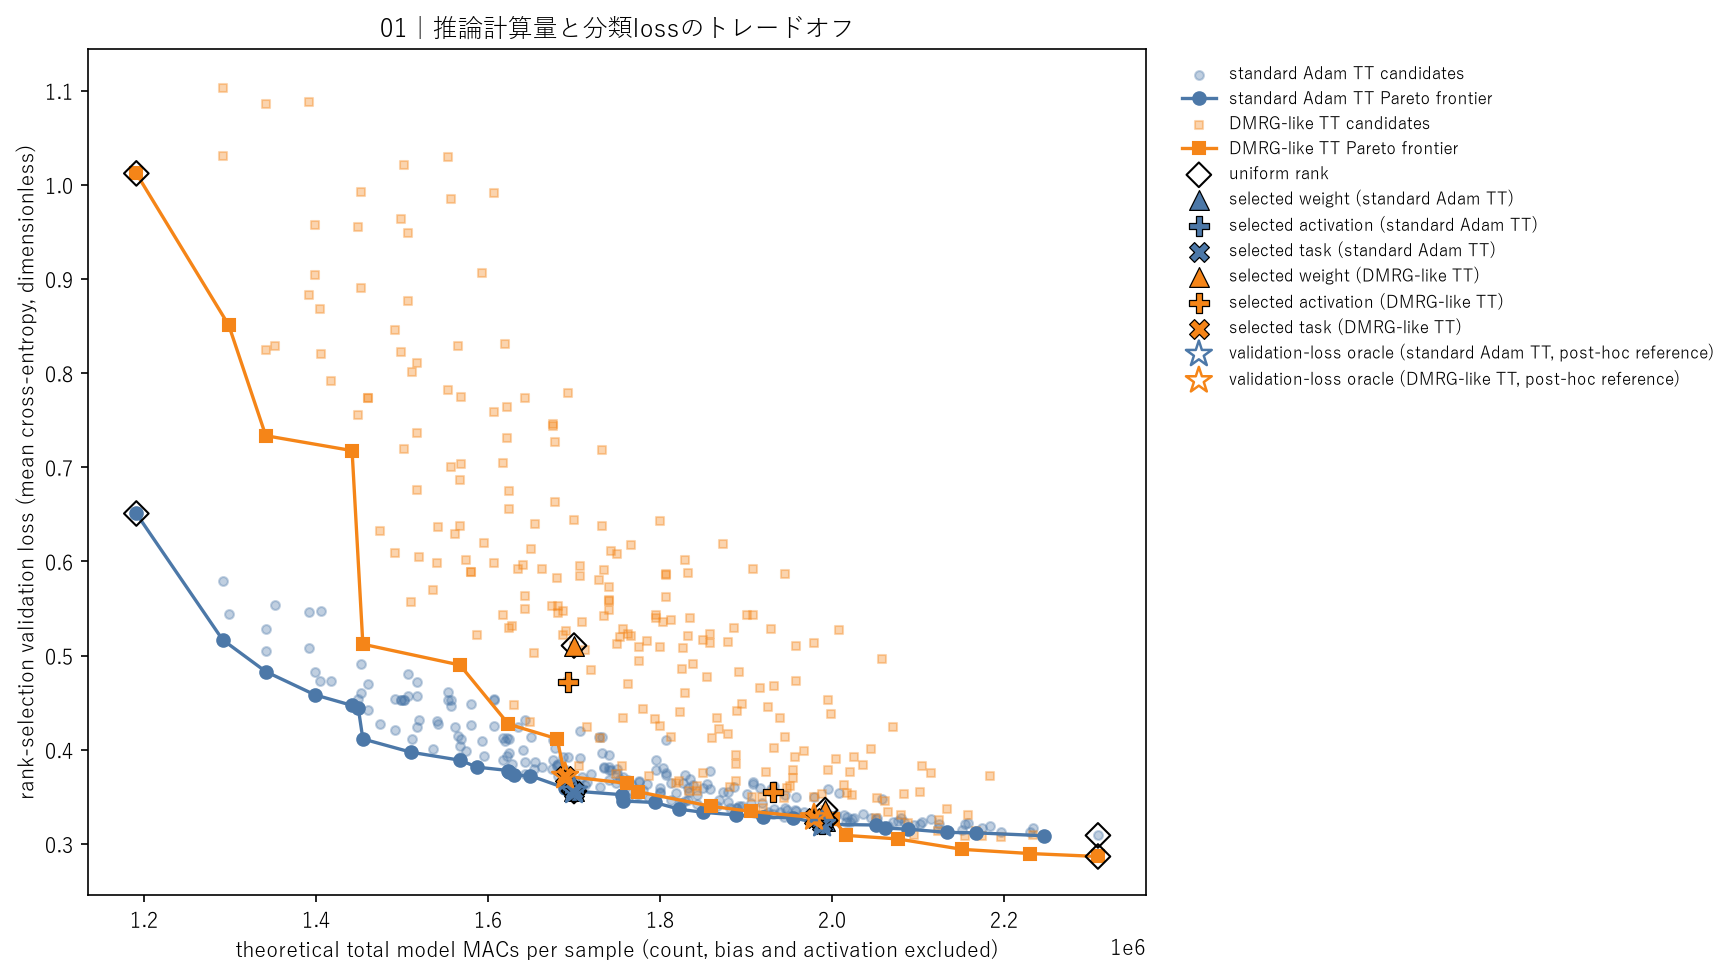

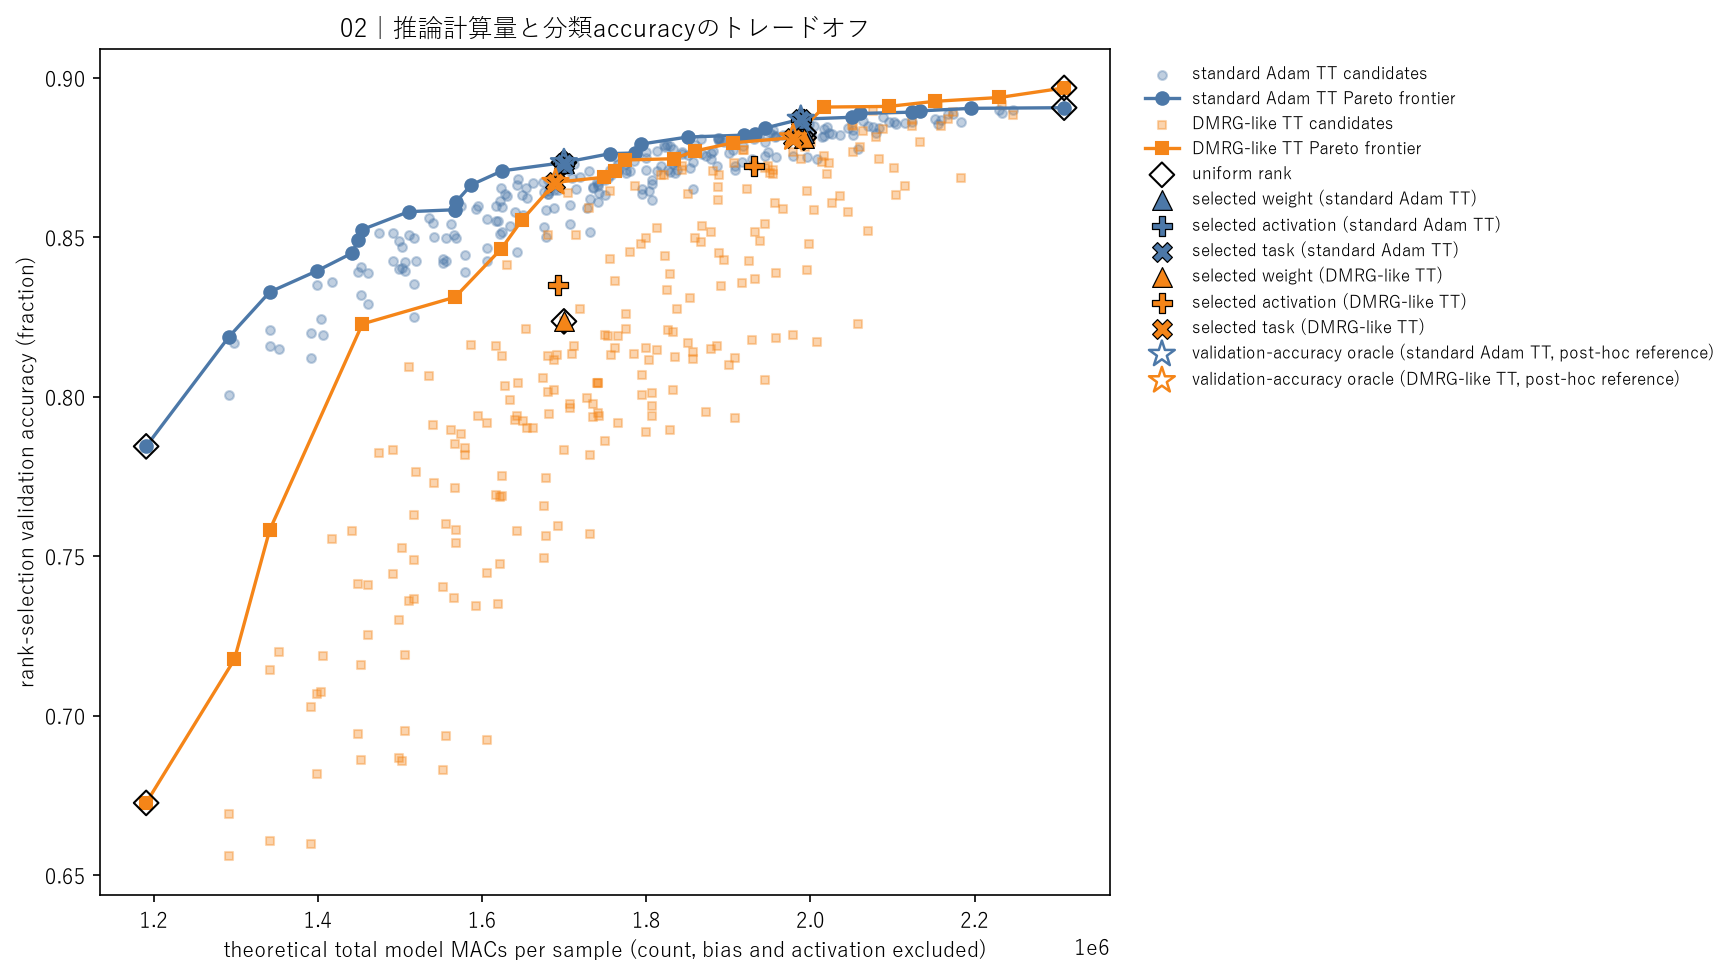

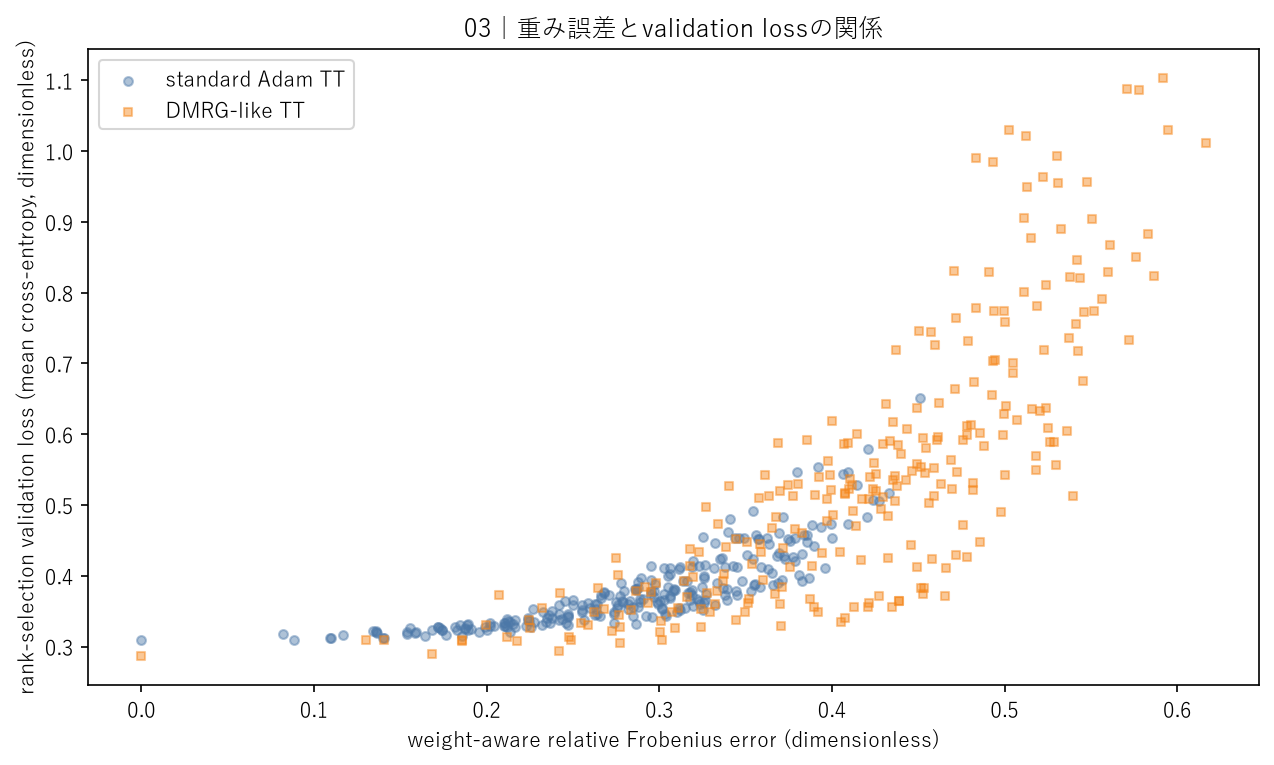

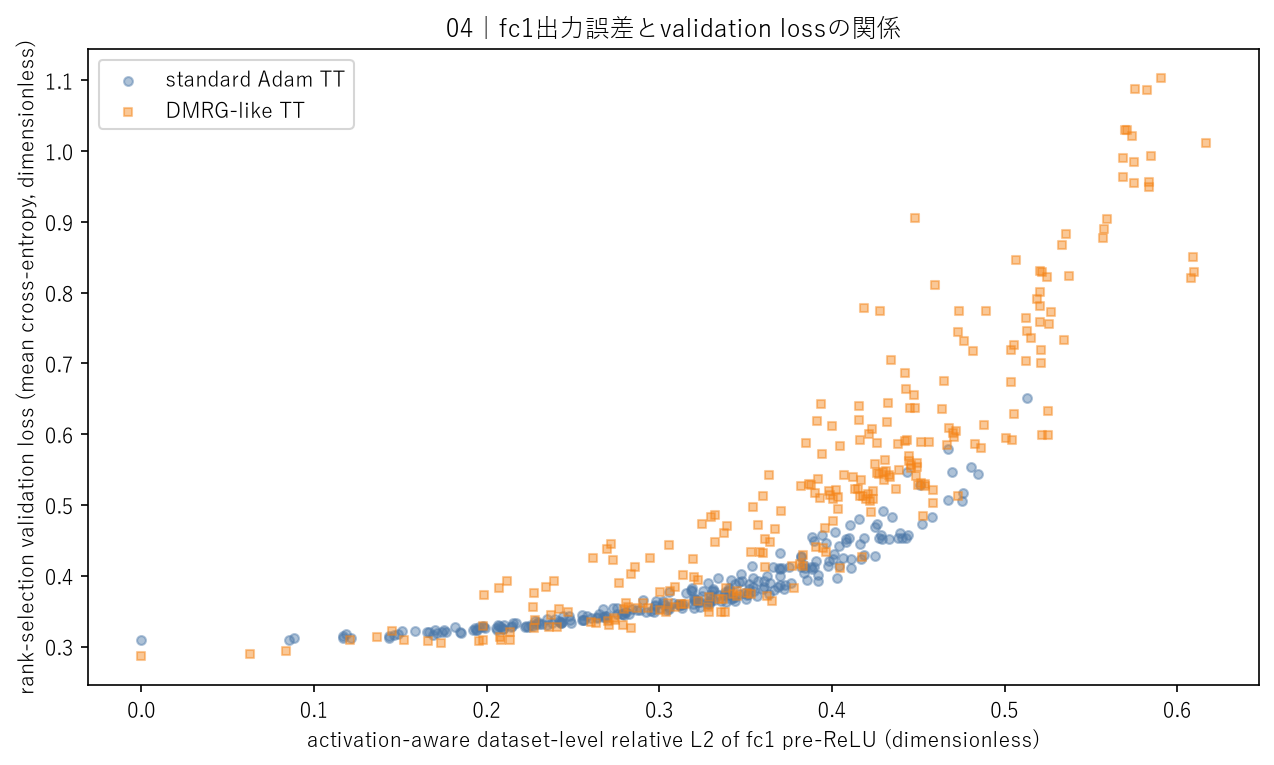

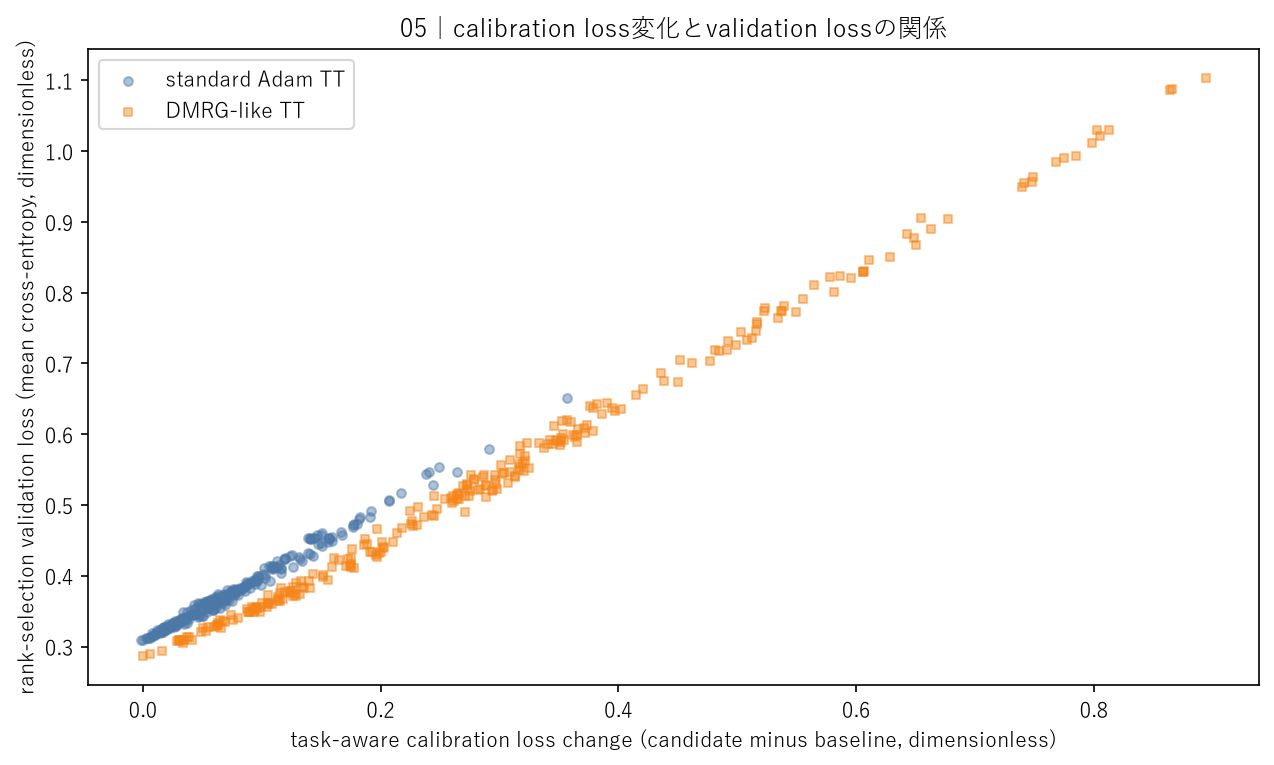

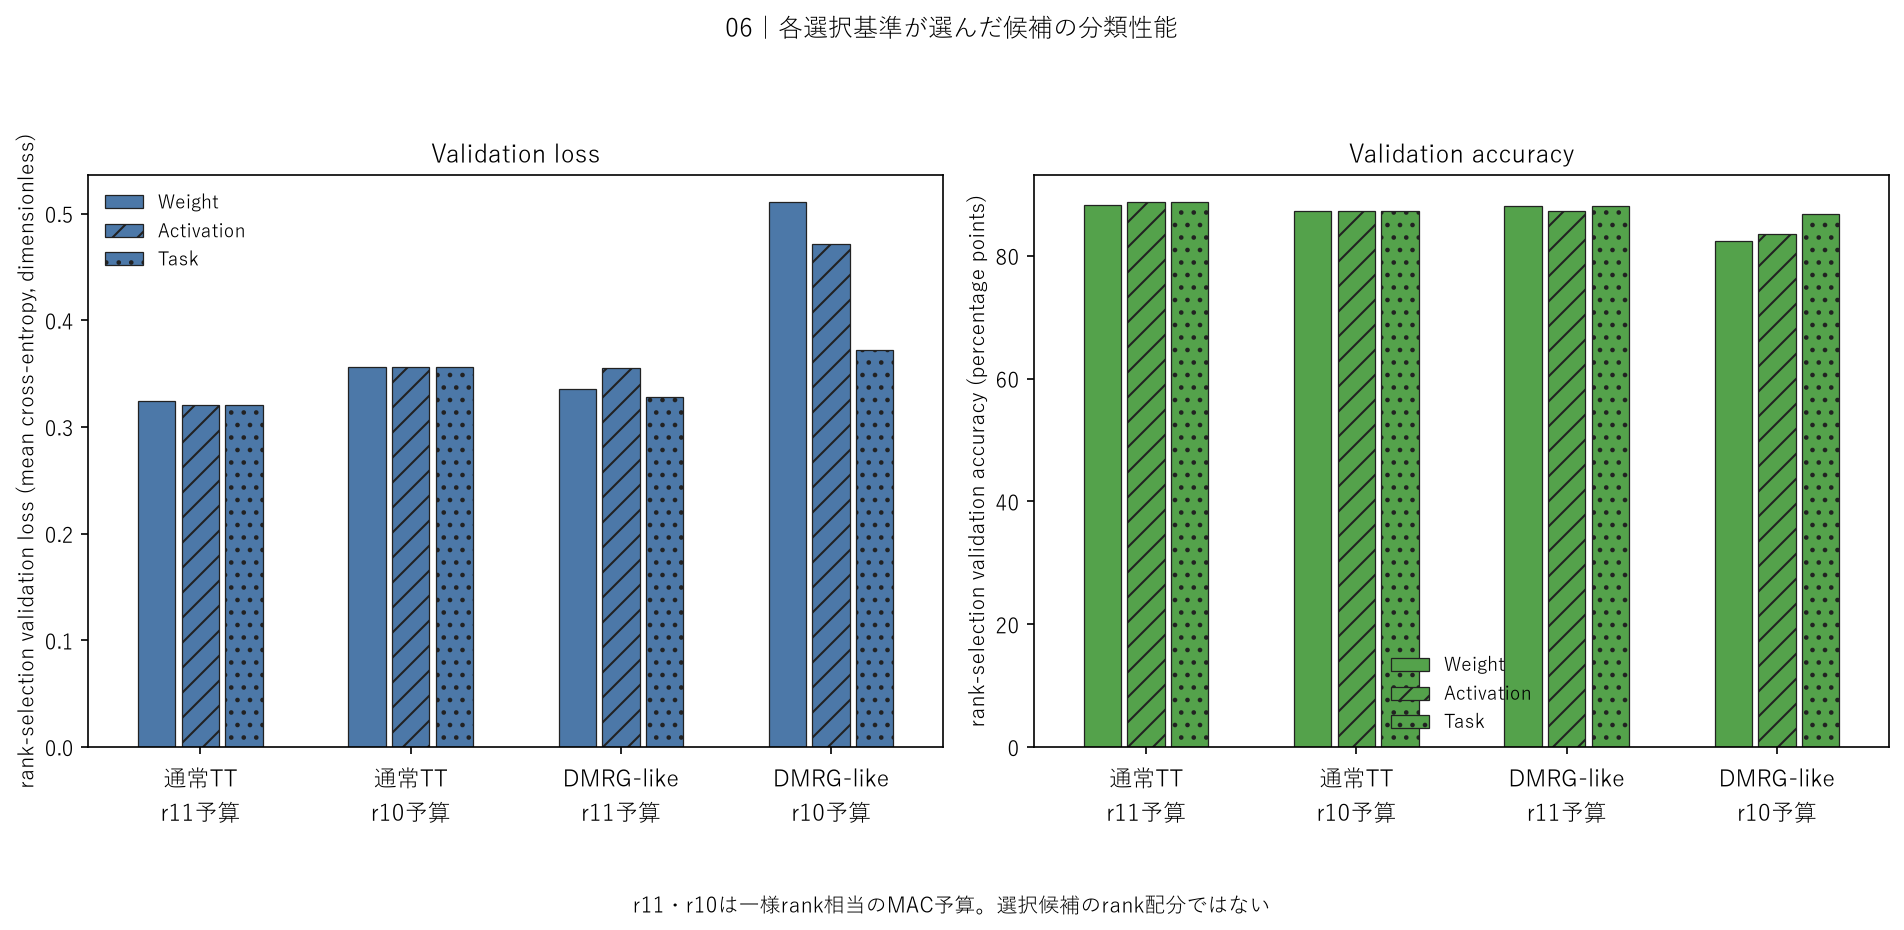

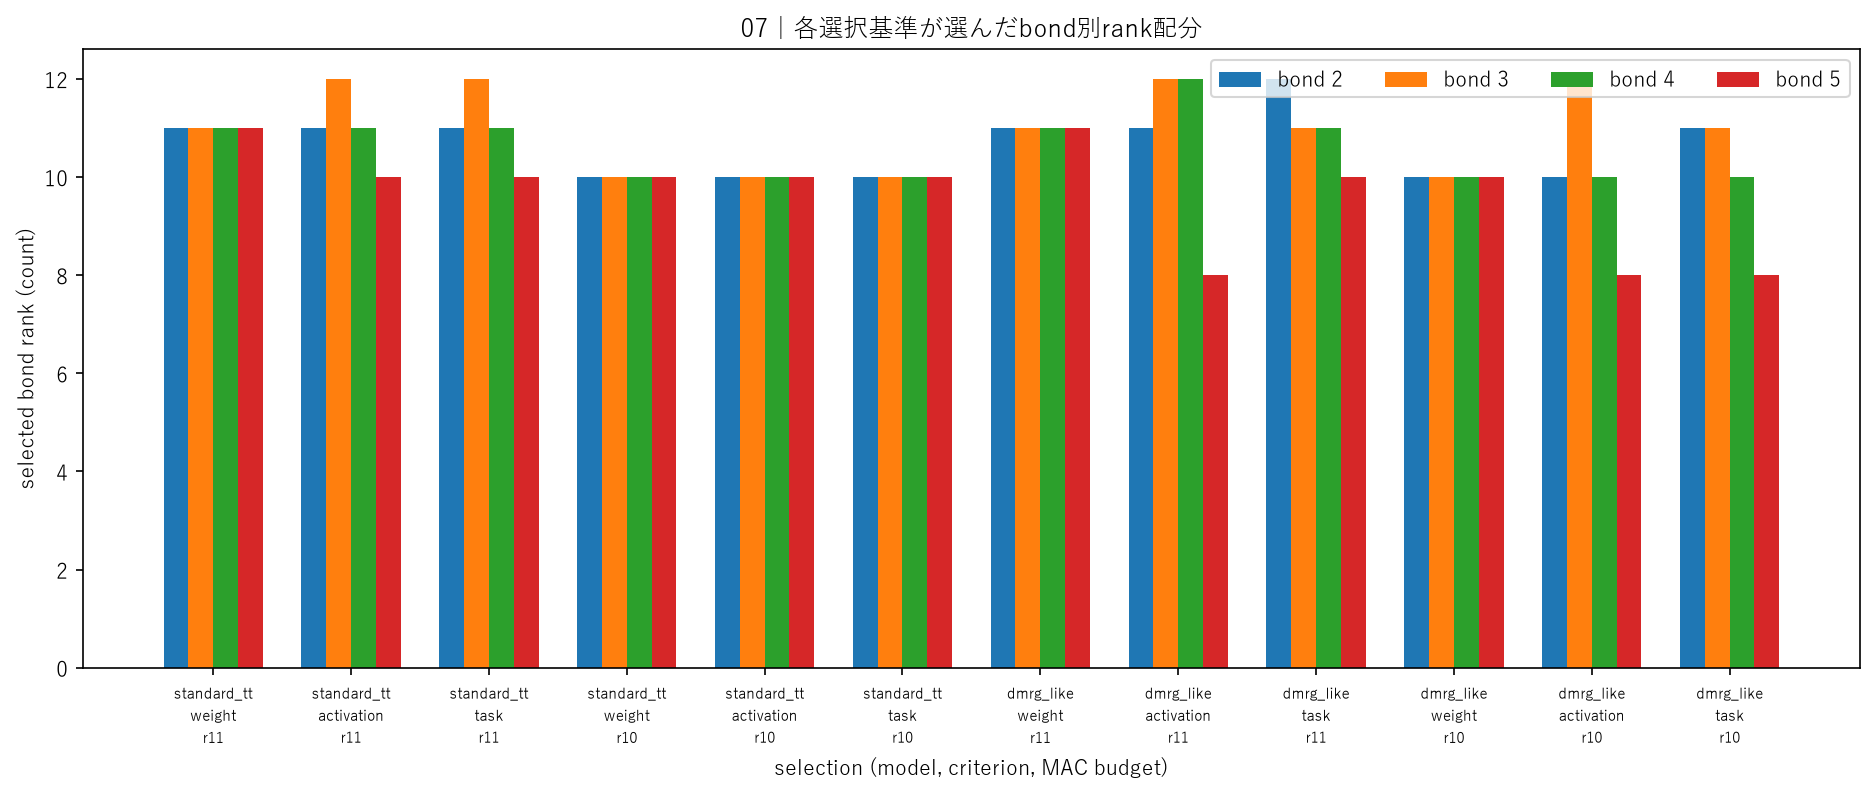

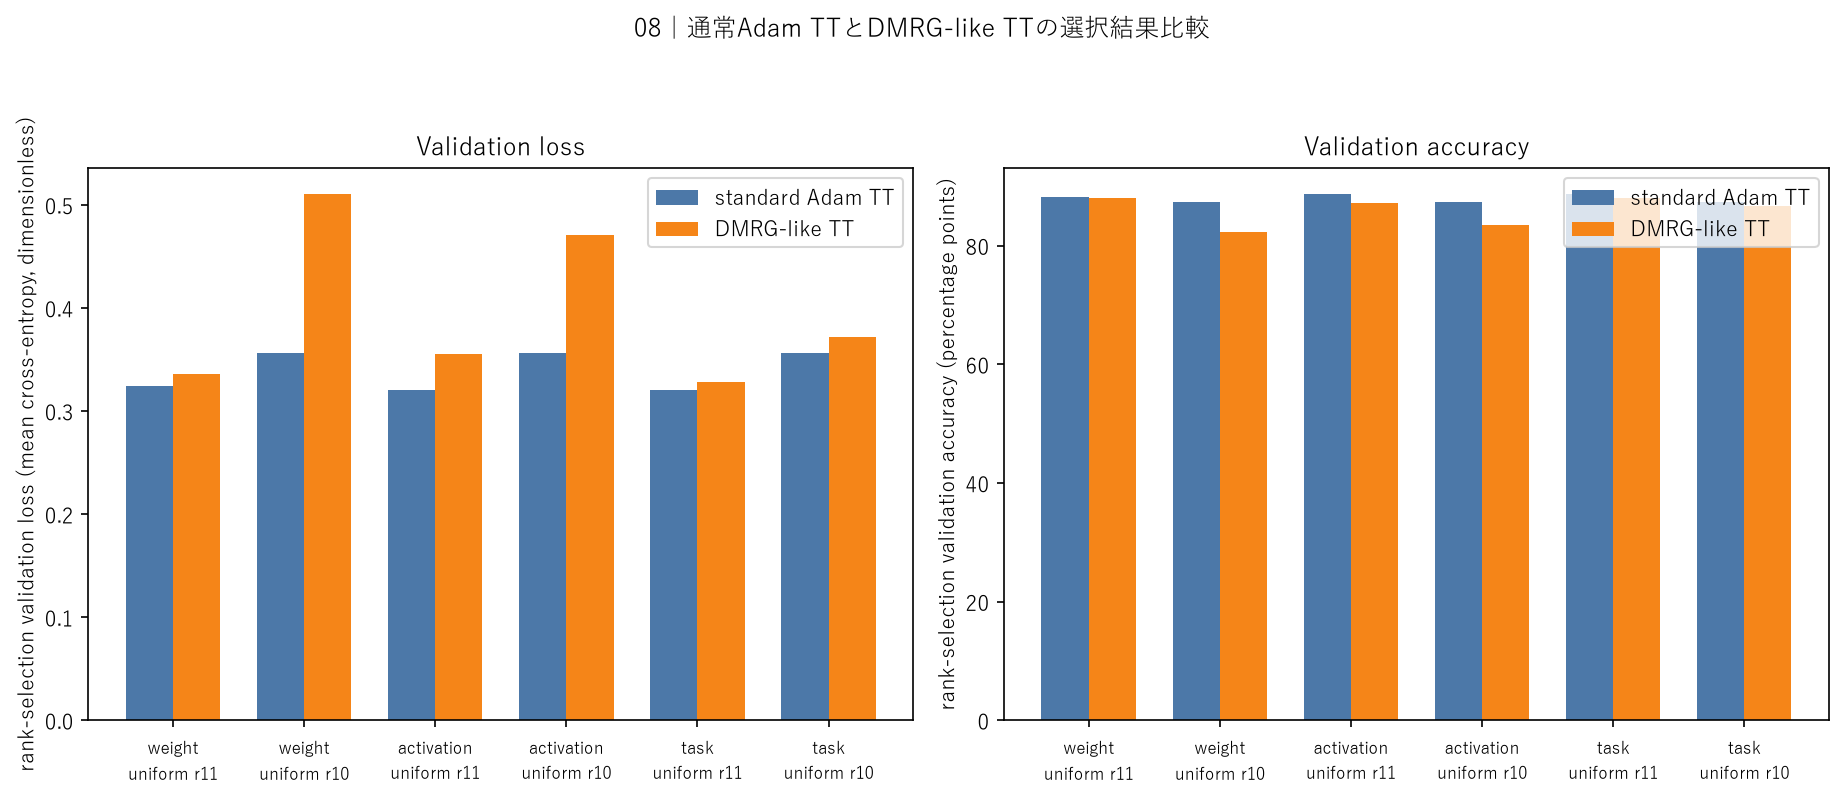

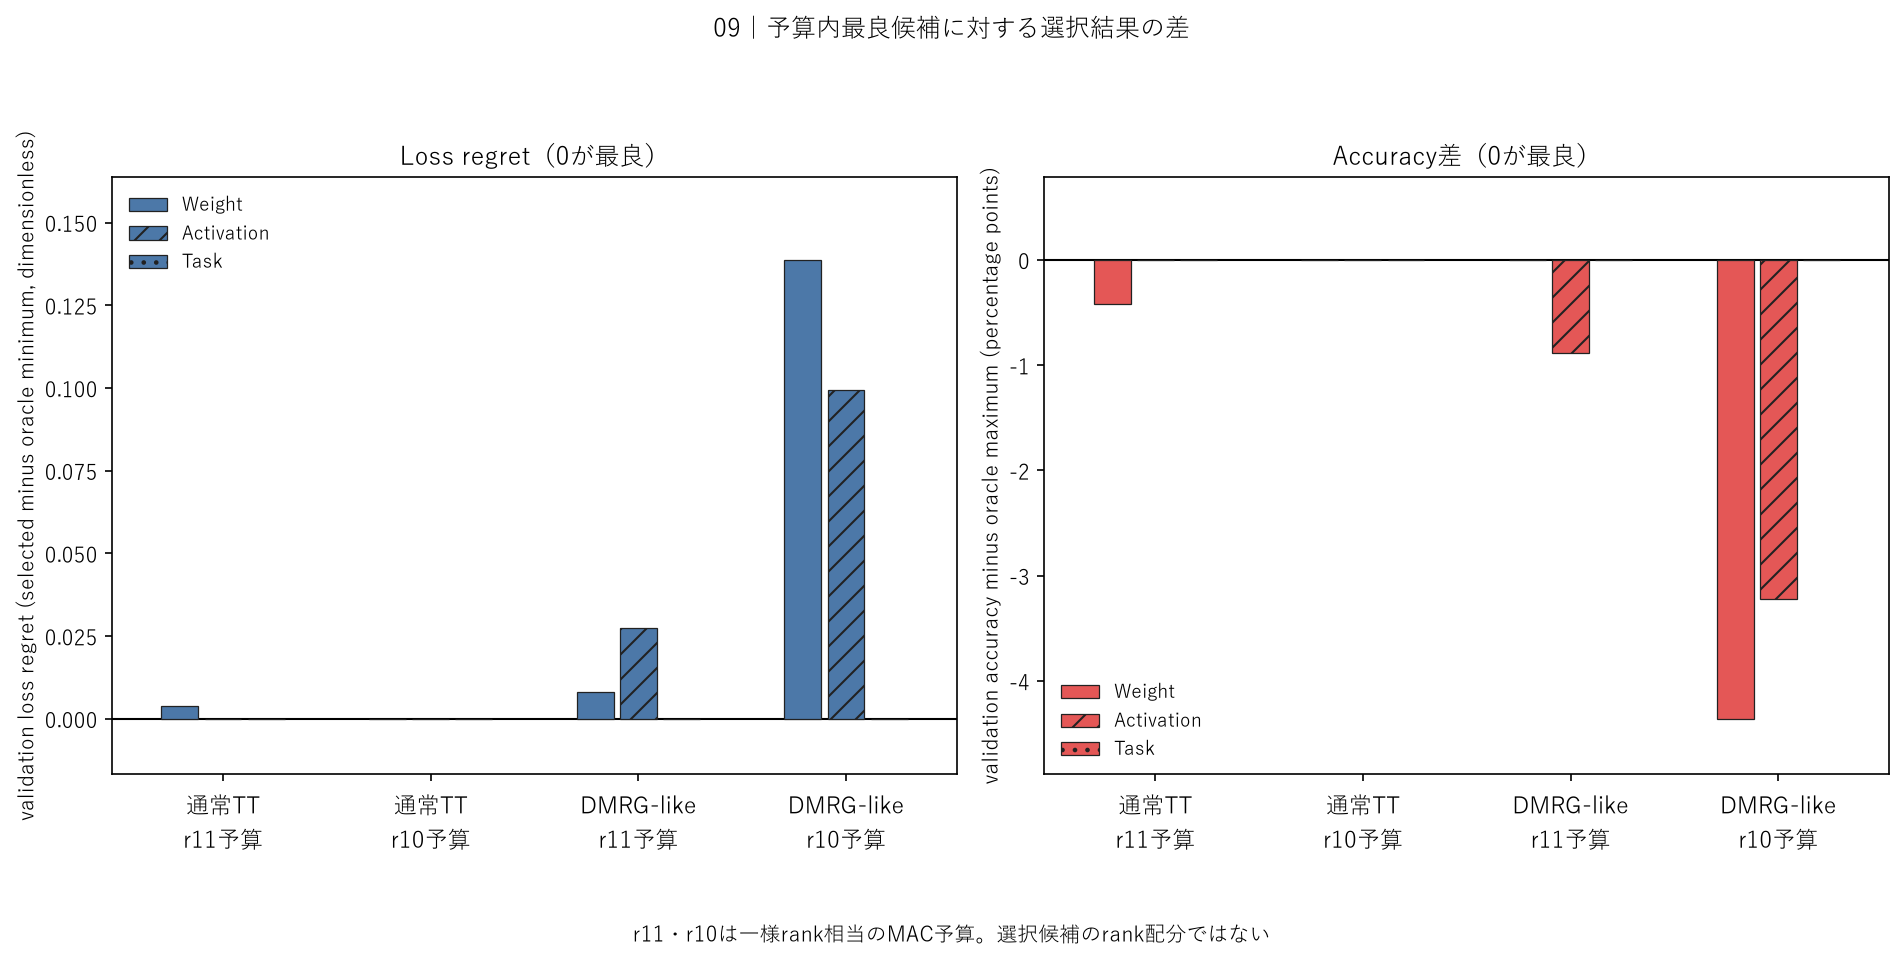

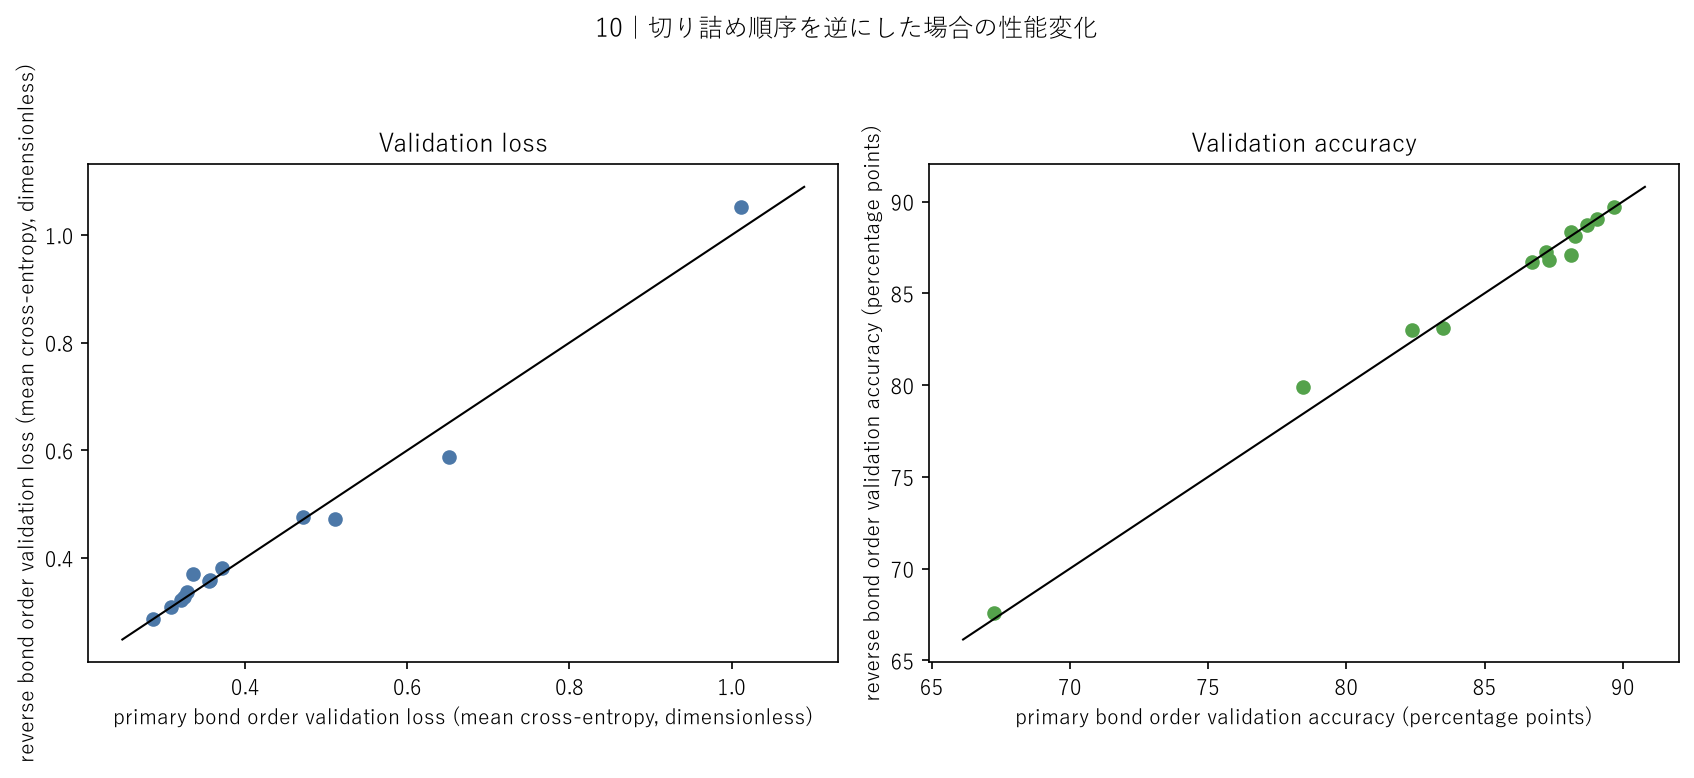

In [143]:
def source_payload(references, hashes):
    payload = []
    for model_type in ("standard_tt", "dmrg_like"):
        reference = references[model_type]
        payload.append(
            {
                "model_type": model_type,
                "sha256": hashes["standard_tt_sha256"] if model_type == "standard_tt" else hashes["dmrg_like_sha256"],
                "generation": reference["generation"],
                "generation_directory": reference["generation_directory"],
                "active_generation": reference["active_generation"],
                "role": reference["role"],
                "baseline_calibration_loss": reference["calibration_loss"],
                "baseline_calibration_accuracy": reference["calibration_accuracy"],
                "baseline_validation_loss": reference["validation_loss"],
                "baseline_validation_accuracy": reference["validation_accuracy"],
                **{key: reference["structure"][key] for key in reference["structure"] if key != "actual_ranks"},
                "actual_ranks": list(reference["structure"]["actual_ranks"]),
            }
        )
    return payload

def run_mode(mode):
    if mode not in {"smoke", "main"}:
        raise RuntimeError(mode)
    clock = {"origin": time.perf_counter(), "stage_started": time.perf_counter()}
    results_dir = results_dir_for(mode)
    data = load_split_and_calibration()
    references, hashes = prepare_references(data)
    implementation_sha256 = current_implementation_sha256()
    run_id = experiment_run_id(
        [
            {"model_type": "standard_tt", "sha256": hashes["standard_tt_sha256"]},
            {"model_type": "dmrg_like", "sha256": hashes["dmrg_like_sha256"], "legacy_sha256": hashes["dmrg_like_legacy_sha256"]},
        ],
        data["split_index_sha256"],
        data["calibration_index_sha256"],
        implementation_sha256,
    )
    assert_same_run(results_dir, run_id)
    results_dir.mkdir(parents=True, exist_ok=True)
    config = {
        "run_id": run_id,
        "notebook_code_sha256": implementation_sha256,
        "mode": mode,
        "training": False,
        "device": EVAL_DEVICE_NAME,
        "dtype": "float32",
        "generation_procedure": "deepcopy; for bond in primary order, canonicalize, merge, right SVD split, replace pair",
        "primary_bond_order": list(PRIMARY_BOND_ORDER),
        "reverse_bond_order": list(REVERSE_BOND_ORDER),
        "rank_choices": list(RANK_CHOICES),
        "candidate_count_per_model": 256 if mode == "main" else len(SMOKE_RANK_TUPLES),
        "calibration_seed": CALIBRATION_SEED,
        "calibration_count": CALIBRATION_COUNT,
        "calibration_index_sha256": data["calibration_index_sha256"],
        "calibration_uses_training_split": True,
        "split_index_sha256": data["split_index_sha256"],
        "sources": source_payload(references, hashes),
        "loss_recheck_atol": LOSS_RECHECK_ATOL,
        "float32_reconstruction_tolerance": FLOAT32_RECONSTRUCTION_TOLERANCE,
        "canonicality_tolerance": CANONICALITY_TOLERANCE,
        "theoretical_macs_include_bias_or_activation": False,
        "main_budgets": ["uniform_rank_11_total_macs", "uniform_rank_10_total_macs"],
        "uniform_rank_8_is_main_budget": False,
    }
    config_path = results_dir / "config.json"
    if config_path.is_file():
        assert_same_run(results_dir, run_id)
    else:
        write_json(config_path, config, results_dir)
    write_json(
        results_dir / "environment.json",
        {"run_id": run_id, "torch": torch.__version__, "device": EVAL_DEVICE_NAME, "training": False},
        results_dir,
    )
    write_json(
        results_dir / "calibration_indices.json",
        {
            "run_id": run_id,
            "seed": CALIBRATION_SEED,
            "count": CALIBRATION_COUNT,
            "index_sha256": data["calibration_index_sha256"],
            "dataset_indices": data["calibration_dataset_indices"],
            "drawn_from": "train_split_50000",
            "same_subset_for_both_models": True,
        },
        results_dir,
    )
    touch_run_state(results_dir, clock, run_id, mode, "setup", "configuration_saved")
    begin_stage(clock, results_dir, run_id, mode, "control", "started")
    control_path = results_dir / "control_verification.json"
    if control_path.is_file():
        saved_control = read_json(control_path)
        if saved_control.get("run_id") != run_id or saved_control.get("passed") is not True:
            raise RuntimeError("既存 control が今回の run で通過済みではありません。上書きしません。")
        controls = saved_control["controls"]
    else:
        controls = [run_rank12_control(references[model_type]) for model_type in ("standard_tt", "dmrg_like")]
        write_json(control_path, {"run_id": run_id, "passed": True, "controls": controls}, results_dir)
    control_seconds = sum(float(item["seconds"]) for item in controls)
    touch_run_state(results_dir, clock, run_id, mode, "control", "stage_finished")
    begin_stage(clock, results_dir, run_id, mode, "calibration", "started")
    tuples = rank_tuples_for(mode)
    calibration = ensure_calibration(results_dir, references, tuples, run_id, clock, mode)
    touch_run_state(results_dir, clock, run_id, mode, "calibration", "stage_finished", len(calibration), len(calibration), list(calibration["seconds"].astype(float)))
    begin_stage(clock, results_dir, run_id, mode, "selection_complete", "started")
    budgets = measured_budgets(calibration) if mode == "main" else measured_budgets_from_available(calibration)
    selection_rows = select_candidates(calibration, budgets, run_id)
    publish_selection(results_dir, selection_rows, run_id)
    selection_bytes = (results_dir / "selection.csv").read_bytes()
    touch_run_state(results_dir, clock, run_id, mode, "selection_complete", "selection_frozen", len(selection_rows), len(selection_rows))
    begin_stage(clock, results_dir, run_id, mode, "validation", "started")
    validation = ensure_validation(results_dir, references, calibration, budgets, selection_rows, run_id, clock, mode)
    if (results_dir / "selection.csv").read_bytes() != selection_bytes:
        raise RuntimeError("validation 後に selection.csv が変化しました。")
    touch_run_state(results_dir, clock, run_id, mode, "validation", "stage_finished", len(validation), len(validation), list(validation["seconds"].astype(float)))
    analysis_origin = time.perf_counter()
    begin_stage(clock, results_dir, run_id, mode, "analysis", "started")
    joined = joined_frame(calibration, validation)
    regret = oracle_and_regret(joined, selection_rows, run_id)
    correlations = spearman_rows(joined, run_id)
    frontier = pareto_rows(joined, run_id)
    metrics_seconds = time.perf_counter() - analysis_origin
    touch_run_state(results_dir, clock, run_id, mode, "analysis", "metrics_ready")
    begin_stage(clock, results_dir, run_id, mode, "reverse_control", "started")
    reverse_rows = run_reverse_control(results_dir, references, joined, selection_rows, run_id, clock, mode)
    reverse_seconds = [float(row["seconds"]) for row in reverse_rows]
    touch_run_state(results_dir, clock, run_id, mode, "reverse_control", "stage_finished", len(reverse_rows), len(reverse_rows), reverse_seconds)
    table_started = time.perf_counter()
    write_csv(results_dir / "calibration_metrics.csv", calibration.to_dict("records"), list(calibration.columns), results_dir)
    write_csv(results_dir / "validation_metrics.csv", validation.to_dict("records"), list(validation.columns), results_dir)
    write_csv(results_dir / "oracle_regret.csv", regret, list(regret[0]), results_dir)
    write_csv(results_dir / "spearman.csv", correlations, list(correlations[0]), results_dir)
    write_csv(results_dir / "pareto_frontier.csv", frontier.to_dict("records"), list(frontier.columns), results_dir)
    write_csv(results_dir / "reverse_order_control.csv", reverse_rows, list(reverse_rows[0]), results_dir)
    uniform = joined[joined["is_uniform"] == True]
    write_csv(results_dir / "uniform_comparison.csv", uniform.to_dict("records"), list(uniform.columns), results_dir)
    selected = joined[joined["candidate_id"].isin([row["candidate_id"] for row in selection_rows])]
    write_csv(results_dir / "selected_comparison.csv", selected.to_dict("records"), list(selected.columns), results_dir)
    table_seconds = time.perf_counter() - table_started
    begin_stage(clock, results_dir, run_id, mode, "figures", "started")
    assert_artifact_run_ids(results_dir, run_id)
    render_figures(results_dir, joined, selection_rows, regret, reverse_rows, frontier)
    figure_seconds = time.perf_counter() - clock["stage_started"]
    touch_run_state(results_dir, clock, run_id, mode, "figures", "stage_finished")
    for reference in references.values():
        if file_sha256(reference["path"]) != reference["sha256"]:
            raise RuntimeError("実験のあとで元 checkpoint が変化しました。")
        if not states_equal(clone_state(reference["model"]), reference["original_state"]):
            raise RuntimeError("実験のあとで元モデルが変化しました。")
    mean_calibration = float(calibration["seconds"].mean())
    mean_validation = float(validation["seconds"].mean())
    mean_reverse = sum(reverse_seconds) / len(reverse_seconds)
    aggregation_and_figures_seconds = metrics_seconds + table_seconds + figure_seconds
    actual_total_seconds = time.perf_counter() - clock["origin"]
    main_candidate_count = len(full_rank_tuples()) * 2
    estimated_reverse_count = 2 * (
        len(SELECTION_CRITERIA) * len(PRIMARY_BUDGET_INTERNAL_RANKS)
        + len(UNIFORM_INTERNAL_RANKS)
        + len(PRIMARY_BUDGET_INTERNAL_RANKS)
    )
    summary = {
        "run_id": run_id,
        "mode": mode,
        "stage": "complete",
        "stop_reason": "completed",
        "candidate_count": int(len(joined)),
        "uniform_rank_8_used_as_main_budget": False,
    }
    if mode == "smoke":
        estimated_calibration = mean_calibration * main_candidate_count
        estimated_validation = mean_validation * main_candidate_count
        estimated_reverse = mean_reverse * estimated_reverse_count
        summary.update(
            {
                "mean_calibration_seconds_per_candidate": mean_calibration,
                "mean_validation_seconds_per_candidate": mean_validation,
                "mean_reverse_seconds_per_candidate": mean_reverse,
                "actual_control_seconds": control_seconds,
                "actual_aggregation_and_figures_seconds": aggregation_and_figures_seconds,
                "estimated_main_candidate_count": main_candidate_count,
                "estimated_main_calibration_seconds": estimated_calibration,
                "estimated_main_validation_seconds": estimated_validation,
                "estimated_main_reverse_candidate_count": estimated_reverse_count,
                "estimated_main_reverse_seconds": estimated_reverse,
                "estimated_main_total_seconds": estimated_calibration + estimated_validation + estimated_reverse + control_seconds + aggregation_and_figures_seconds,
                "reverse_estimate_method": "upper_bound_before_deduplication: 2 models * (3 criteria * 2 budgets + 4 uniform ranks + 2 validation-loss oracles). Smoke reverse count is not scaled to 512.",
                "control_estimate_method": "measured control seconds, not scaled by candidate count",
                "aggregation_estimate_method": "measured aggregation and figure seconds, not scaled by candidate count",
                "actual_smoke_total_seconds": actual_total_seconds,
            }
        )
    else:
        summary.update(
            {
                "actual_mean_calibration_seconds_per_candidate": mean_calibration,
                "actual_mean_validation_seconds_per_candidate": mean_validation,
                "actual_mean_reverse_seconds_per_candidate": mean_reverse,
                "actual_calibration_seconds": float(calibration["seconds"].sum()),
                "actual_validation_seconds": float(validation["seconds"].sum()),
                "actual_reverse_seconds": sum(reverse_seconds),
                "actual_reverse_candidate_count": len(reverse_rows),
                "actual_control_seconds": control_seconds,
                "actual_aggregation_and_figures_seconds": aggregation_and_figures_seconds,
                "actual_total_seconds": actual_total_seconds,
            }
        )
    write_json(results_dir / ("smoke_summary.json" if mode == "smoke" else "main_summary.json"), summary, results_dir)
    touch_run_state(results_dir, clock, run_id, mode, "complete", "completed", stop_reason="completed")
    print(mode, "candidates", len(joined), "run", run_id)

def regenerate_saved_figures():
    results_dir = MAIN_RESULTS_DIR
    if not (results_dir / "config.json").is_file():
        raise RuntimeError("主実験の保存結果が無いため、図は再生成しません。")
    config = read_json(results_dir / "config.json")
    current_hash = current_implementation_sha256()
    saved_hash = config.get("notebook_code_sha256")
    if current_hash != saved_hash:
        # 図再生成は保存済み CSV だけを読む。表示コード変更で hash が変わっても、
        # run_id / selection 不変で担保できるので停止しない。
        print(
            "警告: 実装ハッシュが保存済み config と違います。"
            "評価結果は再計算せず、保存済み表から図だけ再生成します。"
            f" saved={saved_hash} current={current_hash}"
        )
    if "run_id" not in config:
        raise RuntimeError("config.json に run_id がありません。図は上書きしません。")
    assert_artifact_run_ids(results_dir, config["run_id"])
    calibration = pd.read_csv(results_dir / "calibration_metrics.csv")
    validation = pd.read_csv(results_dir / "validation_metrics.csv")
    selection = pd.read_csv(results_dir / "selection.csv").to_dict("records")
    regret = pd.read_csv(results_dir / "oracle_regret.csv").to_dict("records")
    frontier = pd.read_csv(results_dir / "pareto_frontier.csv")
    reverse_rows = pd.read_csv(results_dir / "reverse_order_control.csv").to_dict("records")
    before = (results_dir / "selection.csv").read_bytes()
    render_figures(results_dir, joined_frame(calibration, validation), selection, regret, reverse_rows, frontier)
    if (results_dir / "selection.csv").read_bytes() != before:
        raise RuntimeError("図の再生成で selection.csv が変化しました。")

def main():
    if RUN_SMOKE and RUN_MAIN_EXPERIMENT:
        raise RuntimeError("smoke と主実験は同時に実行しません。")
    if RUN_SMOKE:
        run_mode("smoke")
        return
    if RUN_MAIN_EXPERIMENT:
        run_mode("main")
        return
    if REGENERATE_DISPLAY_ARTIFACTS:
        regenerate_saved_figures()
        return
    print("スイッチはすべて False です。評価と図の生成は実行しません。")

main()
